# Predictive Analytics Term Project - Winter Term 2024/25 - Murat Tutar

In [1]:
import numpy as np
import pandas as pd
import numpy as np 
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report, confusion_matrix
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler

## Day 1

In [2]:
# Your code here

Write down your answers and remarks to your code for Day 1 here

In [3]:
# Load the data from the provided CSV file
data_path = "Rides_daily.csv"
rides_data = pd.read_csv(data_path)

# Display first few rows of the data to understand its structure
rides_data.head()

,ride_start_time,ride_count,ride_date,location_name,temperature_max,temperature_min,temperature_avg,feels_like_max,feels_like_min,feels_like_avg,...,solar_energy,uv_index,severe_weather_risk,sunrise_time,sunset_time,moon_phase,weather_conditions,weather_description,weather_icon,weather_stations
0,2020-01-01 00:00:00,10,2020-01-01,new york,5.0,1.7,3.6,2.8,-2.8,-0.1,...,3.6,2,NaN,2020-01-01T07:20:08,2020-01-01T16:38:55,0.17,"Rain, Partially cloudy",Partly cloudy throughout the day with morning ...,rain,"72505394728,72055399999,KLGA,KJRB,KNYC,F1417,7..."
1,2020-01-01 01:00:00,14,2020-01-01,new york,5.0,1.7,3.6,2.8,-2.8,-0.1,...,3.6,2,NaN,2020-01-01T07:20:08,2020-01-01T16:38:55,0.17,"Rain, Partially cloudy",Partly cloudy throughout the day with morning ...,rain,"72505394728,72055399999,KLGA,KJRB,KNYC,F1417,7..."
2,2020-01-01 02:00:00,9,2020-01-01,new york,5.0,1.7,3.6,2.8,-2.8,-0.1,...,3.6,2,NaN,2020-01-01T07:20:08,2020-01-01T16:38:55,0.17,"Rain, Partially cloudy",Partly cloudy throughout the day with morning ...,rain,"72505394728,72055399999,KLGA,KJRB,KNYC,F1417,7..."
3,2020-01-01 03:00:00,6,2020-01-01,new york,5.0,1.7,3.6,2.8,-2.8,-0.1,...,3.6,2,NaN,2020-01-01T07:20:08,2020-01-01T16:38:55,0.17,"Rain, Partially cloudy",Partly cloudy throughout the day with morning ...,rain,"72505394728,72055399999,KLGA,KJRB,KNYC,F1417,7..."
4,2020-01-01 04:00:00,2,2020-01-01,new york,5.0,1.7,3.6,2.8,-2.8,-0.1,...,3.6,2,NaN,2020-01-01T07:20:08,2020-01-01T16:38:55,0.17,"Rain, Partially cloudy",Partly cloudy throughout the day with morning ...,rain,"72505394728,72055399999,KLGA,KJRB,KNYC,F1417,7..."


In [4]:
# Creating an overview table for each variable
overview = pd.DataFrame({
    "Column": rides_data.columns,
    "Data Type": rides_data.dtypes,
    "Unique Values": rides_data.nunique(),
    "Missing Values": rides_data.isna().sum(),
    "Example Value": rides_data.iloc[0]
}).reset_index(drop=True)

overview

,Column,Data Type,Unique Values,Missing Values,Example Value
0,ride_start_time,object,22487,0,2020-01-01 00:00:00
1,ride_count,int64,429,0,10
2,ride_date,object,973,0,2020-01-01
3,location_name,object,1,0,new york
4,temperature_max,float64,266,0,5.0
5,temperature_min,float64,242,0,1.7
6,temperature_avg,float64,321,0,3.6
7,feels_like_max,float64,339,0,2.8
8,feels_like_min,float64,304,0,-2.8
9,feels_like_avg,float64,363,0,-0.1


In [5]:
# Question b: Calculating the number of days and hours in the dataset

# Converting 'ride_start_time' to datetime to calculate time span
rides_data['ride_start_time'] = pd.to_datetime(rides_data['ride_start_time'])

# Calculating total days and hours in the dataset
total_days = rides_data['ride_date'].nunique()
total_hours = rides_data['ride_start_time'].nunique()

total_days, total_hours

(973, 22487)

The dataset spans 973 days with 22,487 hours worth of observations.

In [6]:
# Further analysis to determine average hours of data per day

# Grouping by 'ride_date' to count the number of hourly entries per day
daily_hours = rides_data.groupby('ride_date').size()

# Calculating average hours per day
average_hours_per_day = daily_hours.mean()

average_hours_per_day

23.110996916752313

On average, we have approximately 23.1 hours of data per day in the dataset. This suggests that there may be some missing hourly entries on certain days (since a day is 24 hours long). It is possibly because of the missing data on hours when there is no ride.

In [7]:
# Question c: Checking if we have the same number of observations for each hour and day

# Creating a pivot table to count occurrences of each hour for each day
hourly_distribution = rides_data.groupby(['ride_date', rides_data['ride_start_time'].dt.hour]).size().unstack(fill_value=0)

# Checking if every hour in each day has an entry (1 entry per hour means same observation for each hour)
hourly_consistency = (hourly_distribution != 0).all(axis=1)

# Calculating the percentage of days with full hourly data
full_hourly_data_percentage = hourly_consistency.mean() * 100

full_hourly_data_percentage

59.91778006166495

Approximately 59.9% of the days in the dataset have a complete set of hourly observations, meaning that for about 40.1% of days, data for some hours is missing.

This is significant because if hours with no rides are missing, the average number of rides per hour could be overestimated. By excluding zero-ride hours, the dataset might give the impression of higher ride activity than actually occurred. Including these zero-ride hours would provide a more accurate representation of average ride frequency.

Below is the distribution of the days with respect to number of hourly observations.

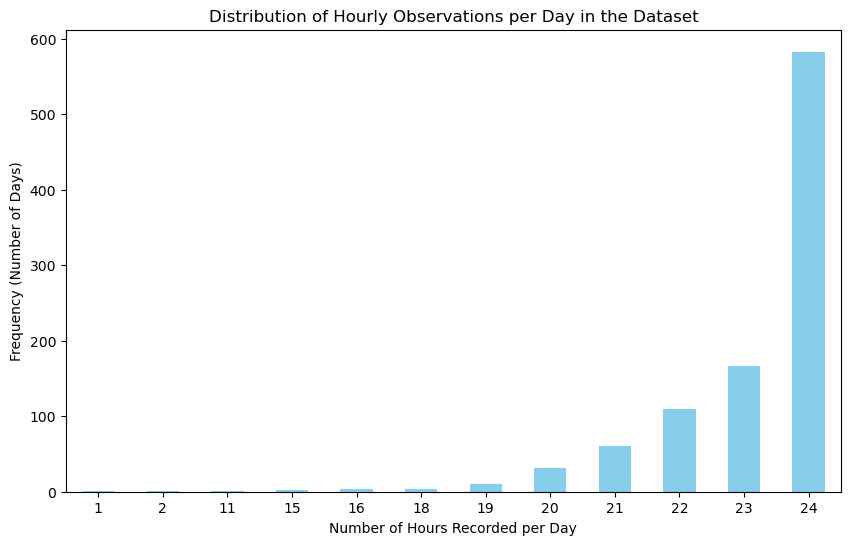

In [8]:
# Calculating the frequency distribution of hourly data per day
hourly_counts_per_day = daily_hours.value_counts().sort_index()

# Displaying nominal values for days with varying hourly observations
hourly_counts_per_day_display = hourly_counts_per_day.to_frame(name="Number of Days")
hourly_counts_per_day_display.index.name = "Hours per Day"

# Plotting the distribution of hours per day
plt.figure(figsize=(10, 6))
hourly_counts_per_day.plot(kind='bar', color='skyblue')
plt.xlabel("Number of Hours Recorded per Day")
plt.ylabel("Frequency (Number of Days)")
plt.title("Distribution of Hourly Observations per Day in the Dataset")
plt.xticks(rotation=0)
plt.show()

In [9]:
print(hourly_counts_per_day)

Hours per Day
1       1
2       1
11      1
15      2
16      3
18      4
19     10
20     31
21     60
22    110
23    167
24    583
Name: count, dtype: int64


In other words, on 583 days we do not have a missing data and at each hour there is an observation.
On 167 days, there is only one missing hour because of no new ride.
On 110 days, there are two missing hours because of no new ride.
...
...
Overall, 583 days have a complete set and 390 have missing.
This complies with the previous ratio we found: 59.9%

As said before, this result is significant because if hours with no rides are missing, the average number of rides per hour could be overestimated. 
By excluding zero-ride hours, the dataset might give the impression of higher ride activity than actually occurred. 
Including these zero-ride hours would provide a more accurate representation of average ride frequency.

In [10]:
# Question d: Creating four meaningful charts

# Setting up the four charts:
# 1. Bar chart of average ride counts per day of the week
# 2. Histogram of ride counts to see the distribution
# 3. Boxplot of ride counts by month to observe seasonal trends
# 4. Scatter plot of ride counts vs. temperature_avg

# Converting 'ride_date' to datetime format and extracting day of week and month
rides_data['ride_date'] = pd.to_datetime(rides_data['ride_date'])
rides_data['day_of_week'] = rides_data['ride_date'].dt.day_name()
rides_data['month'] = rides_data['ride_date'].dt.month

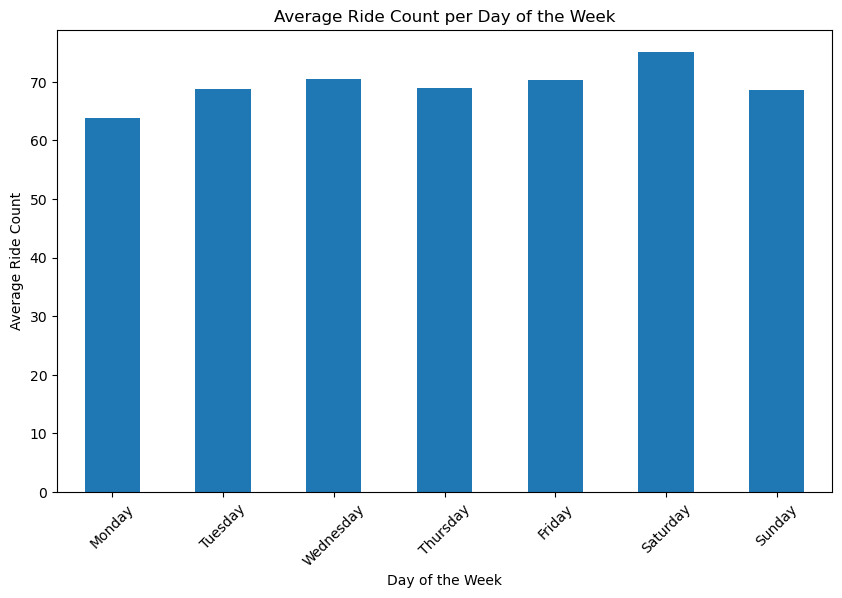

In [11]:
# 1. Bar chart: Average ride count per day of the week
plt.figure(figsize=(10, 6))
rides_data.groupby('day_of_week')['ride_count'].mean().reindex([
    'Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']).plot(kind='bar')
plt.title("Average Ride Count per Day of the Week")
plt.xlabel("Day of the Week")
plt.ylabel("Average Ride Count")
plt.xticks(rotation=45)
plt.show()

Interpretation #1
Bar Chart - Average Ride Count per Day of the Week:
This chart shows the average number of rides for each day of the week, indicating that ride frequency is fairly consistent, with a slight increase on weekends.

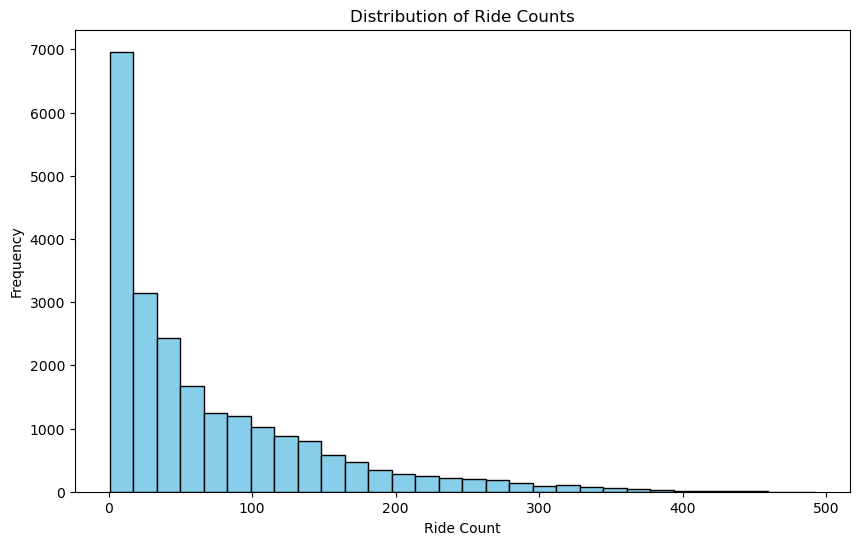

In [12]:
# 2. Histogram: Distribution of ride counts
plt.figure(figsize=(10, 6))
plt.hist(rides_data['ride_count'], bins=30, color='skyblue', edgecolor='black')
plt.title("Distribution of Ride Counts")
plt.xlabel("Ride Count")
plt.ylabel("Frequency")
plt.show()

Interpretation #2
Histogram - Distribution of Ride Counts: 
This histogram reveals a right-skewed distribution, where lower ride counts are more frequent, and higher counts taper off, suggesting that most hours have relatively few rides.

<Figure size 1000x600 with 0 Axes>

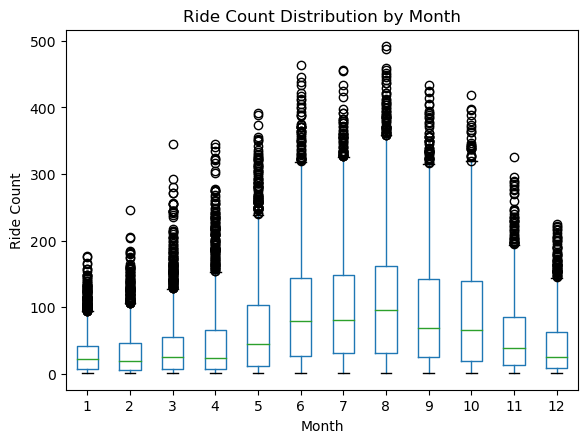

In [13]:
# 3. Boxplot: Ride count by month
plt.figure(figsize=(10, 6))
rides_data.boxplot(column='ride_count', by='month', grid=False)
plt.title("Ride Count Distribution by Month")
plt.suptitle("")
plt.xlabel("Month")
plt.ylabel("Ride Count")
plt.show()

Interpretation #3
Boxplot - Ride Count Distribution by Month: 
This boxplot shows monthly variations in ride counts, with higher counts in warmer months, supporting the hypothesis that ride frequency increases in summer.

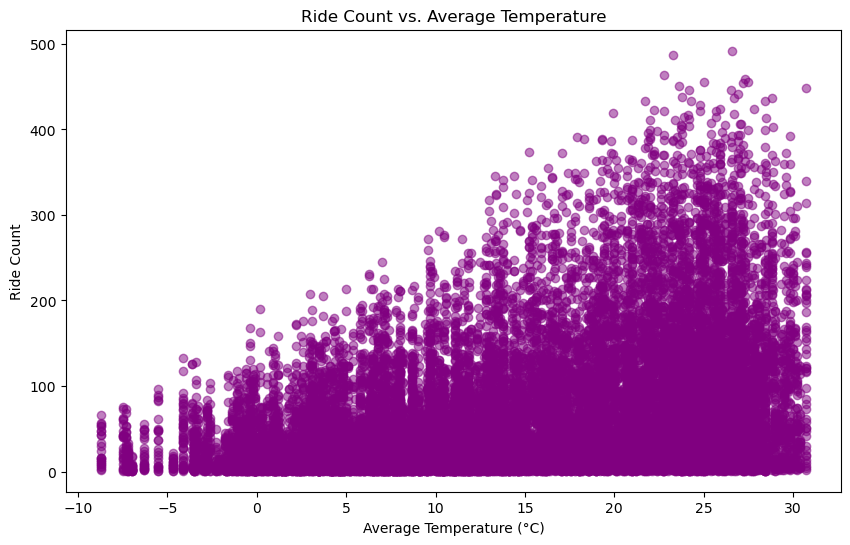

In [14]:
# 4. Scatter plot: Ride count vs. temperature_avg
plt.figure(figsize=(10, 6))
plt.scatter(rides_data['temperature_avg'], rides_data['ride_count'], alpha=0.5, color='purple')
plt.title("Ride Count vs. Average Temperature")
plt.xlabel("Average Temperature (°C)")
plt.ylabel("Ride Count")
plt.show()

Interpretation #4
Scatter Plot - Ride Count vs. Average Temperature: This scatter plot indicates a positive correlation between ride counts and average temperature, with higher temperatures generally corresponding to more rides.

In [15]:
# Adjusting the selection of columns based on those that are present in the dataset
# Selecting key variables for the revised pair plot

subset_data = rides_data[['ride_count', 'temperature_avg', 'feels_like_avg', 'humidity_percent', 'precipitation_amount', 
    'snowfall', 'wind_speed', 'sea_level_pressure', 'cloud_coverage', 'visibility_distance', 
    'solar_radiation', 'solar_energy', 'uv_index']]
subset_data = subset_data.dropna()  # Dropping NaNs for smooth plotting

# Calculating the correlation matrix to find the strongest relationships among selected variables
correlation_matrix = subset_data.corr()

# Displaying the correlation matrix to identify the strongest correlations with ride_count
correlation_matrix['ride_count'].sort_values(ascending=False)


ride_count              1.000000
temperature_avg         0.390432
feels_like_avg          0.385408
uv_index                0.288487
solar_energy            0.266795
solar_radiation         0.266774
visibility_distance     0.117596
humidity_percent       -0.022396
sea_level_pressure     -0.028837
snowfall               -0.033874
precipitation_amount   -0.041691
cloud_coverage         -0.044461
wind_speed             -0.096811
Name: ride_count, dtype: float64

Above is the correlation matrix that I took from my subset.
At first sight, temperature_avg, feels_like_avg, and uv_index seem to be the best variables to choose for meaningful plots.
However, by using common sense and statistical thinking, we can say that actually we should also look for the correlation between the variables.
Because if the chosen variables are very correlated with each other, then choosing one of them would be enough and the other will be meaningless.
This is likely the case for temperature_avg and feels_like_avg, as the average and felt temperature are expected to be highly correlated.
Similarly; uv_index, solar_energy, and solar radiation are also expected to be highly correlated.
Hence, we calculate below.

In [16]:
# Calculating the correlation matrix for the predictor variables to check for redundancy
predictor_correlation_matrix = subset_data[['ride_count', 'temperature_avg', 'feels_like_avg', 'humidity_percent', 'precipitation_amount', 
    'snowfall', 'wind_speed', 'sea_level_pressure', 'cloud_coverage', 'visibility_distance', 
    'solar_radiation', 'solar_energy', 'uv_index']].corr()

# Displaying the correlation matrix for analysis
predictor_correlation_matrix

,ride_count,temperature_avg,feels_like_avg,humidity_percent,precipitation_amount,snowfall,wind_speed,sea_level_pressure,cloud_coverage,visibility_distance,solar_radiation,solar_energy,uv_index
ride_count,1.000000,0.390432,0.385408,-0.022396,-0.041691,-0.033874,-0.096811,-0.028837,-0.044461,0.117596,0.266774,0.266795,0.288487
temperature_avg,0.390432,1.000000,0.997672,0.222890,0.052484,-0.076859,-0.163896,-0.228882,-0.167378,0.178210,0.550468,0.548190,0.541852
feels_like_avg,0.385408,0.997672,1.000000,0.224278,0.049251,-0.081246,-0.182750,-0.225516,-0.168877,0.180998,0.547766,0.545403,0.541041
humidity_percent,-0.022396,0.222890,0.224278,1.000000,0.321749,0.032497,0.051068,-0.279910,0.497114,-0.546253,-0.445220,-0.446070,-0.426633
precipitation_amount,-0.041691,0.052484,0.049251,0.321749,1.000000,0.014838,0.191532,-0.215214,0.262518,-0.322633,-0.214119,-0.215016,-0.213414
snowfall,-0.033874,-0.076859,-0.081246,0.032497,0.014838,1.000000,0.017408,0.073503,0.041863,-0.050709,-0.059506,-0.059689,-0.065149
wind_speed,-0.096811,-0.163896,-0.182750,0.051068,0.191532,0.017408,1.000000,-0.190427,0.190940,-0.144008,-0.207000,-0.205593,-0.210295
sea_level_pressure,-0.028837,-0.228882,-0.225516,-0.279910,-0.215214,0.073503,-0.190427,1.000000,-0.314471,0.200985,0.064583,0.064573,0.048505
cloud_coverage,-0.044461,-0.167378,-0.168877,0.497114,0.262518,0.041863,0.190940,-0.314471,1.000000,-0.524645,-0.561697,-0.561392,-0.509682
visibility_distance,0.117596,0.178210,0.180998,-0.546253,-0.322633,-0.050709,-0.144008,0.200985,-0.524645,1.000000,0.423890,0.424069,0.459327


The correlation matrix reveals a very high correlation (0.997) between temperature_avg and feels_like_avg, confirming they are essentially interchangeable. Additionally, uv_index, solar_radiation, solar_energy have a strong correlation (0.94 to 0.99), suggesting that using more than one of them might also be redundant.

In this case, the 3 variables we choose are: temperature_avg, uv_index, and visibility_distance.
This final selection balances independent predictors, capturing varied weather effects on ride activity.

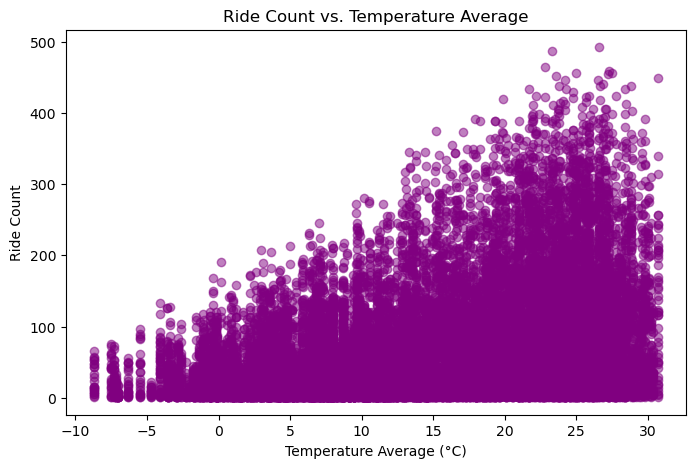

In [17]:
# Creating scatter plots for the selected independent variables: Temperature Average, UV Index, and Visibility Distance

# 1. Scatter plot: Ride Count vs. Temperature Average
plt.figure(figsize=(8, 5))
plt.scatter(subset_data['temperature_avg'], subset_data['ride_count'], alpha=0.5, color='purple')
plt.title("Ride Count vs. Temperature Average")
plt.xlabel("Temperature Average (°C)")
plt.ylabel("Ride Count")
plt.show()

Interpretation #1
Ride Count vs. Temperature Average: 
As expected, there’s a positive correlation—ride counts increase with warmer temperatures, indicating that people prefer to ride in warmer weather.

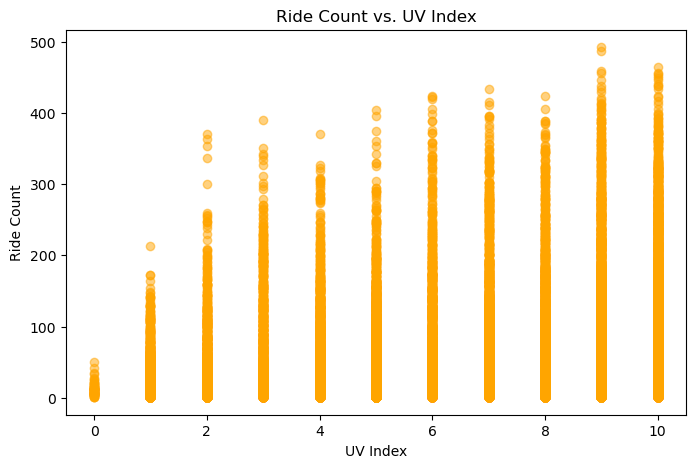

In [18]:
# 2. Scatter plot: Ride Count vs. UV Index
plt.figure(figsize=(8, 5))
plt.scatter(subset_data['uv_index'], subset_data['ride_count'], alpha=0.5, color='orange')
plt.title("Ride Count vs. UV Index")
plt.xlabel("UV Index")
plt.ylabel("Ride Count")
plt.show()

Interpretation 2
Ride Count vs. UV Index: 
This positive trend suggests that higher UV levels, often signaling sunnier days, are associated with more rides, reinforcing the link between good weather and ride frequency.

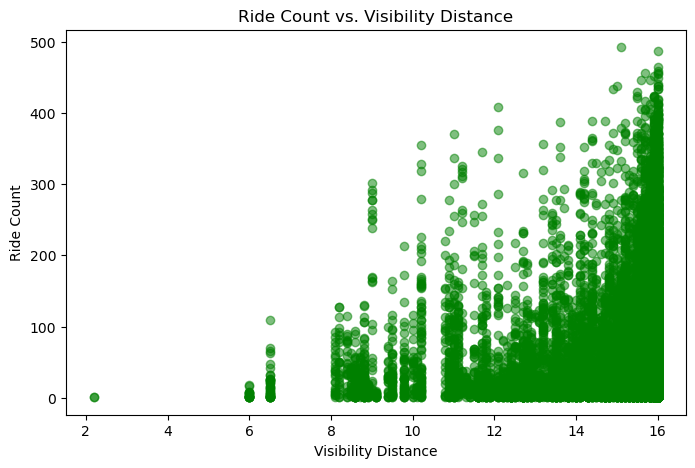

In [19]:
# 3. Scatter plot: Ride Count vs. Visibility Distance
plt.figure(figsize=(8, 5))
plt.scatter(subset_data['visibility_distance'], subset_data['ride_count'], alpha=0.5, color='green')
plt.title("Ride Count vs. Visibility Distance")
plt.xlabel("Visibility Distance")
plt.ylabel("Ride Count")
plt.show()

Interpretation 3
Ride Count vs. Visibility Distance: 
While the correlation is weaker, there is a slight positive relationship. Improved visibility may correlate with better weather conditions, encouraging more people to ride.

## Day 2

In [20]:
# Import necessary libraries for modeling
from sklearn.linear_model import LinearRegression
import statsmodels.api as sm

# Additional Feature Engineering based on the new insight

# Convert ride_start_time to datetime to extract hour for time-based trends
rides_data['ride_start_time'] = pd.to_datetime(rides_data['ride_start_time'])
rides_data['hour'] = rides_data['ride_start_time'].dt.hour

# Creating a binary variable for nighttime (1 if it's night, i.e., 0-5 AM, 0 otherwise)
rides_data['night_time'] = rides_data['hour'].apply(lambda x: 1 if x < 6 else 0)

# Creating a binary variable for evening rush hour (1 if it's 4-8 PM, 0 otherwise)
rides_data['evening_rush'] = rides_data['hour'].apply(lambda x: 1 if 16 <= x <= 20 else 0)

# Creating a weekend binary variable (1 if it's a weekend, 0 otherwise)
rides_data['day_of_week'] = pd.to_datetime(rides_data['ride_date']).dt.day_name()
rides_data['weekend'] = rides_data['day_of_week'].isin(['Saturday', 'Sunday']).astype(int)

# Creating a season feature based on month
rides_data['month'] = pd.to_datetime(rides_data['ride_date']).dt.month
rides_data['season'] = rides_data['month'].apply(lambda x: 'Winter' if x in [12, 1, 2] else 
                                                 ('Spring' if x in [3, 4, 5] else
                                                 ('Summer' if x in [6, 7, 8] else 'Fall')))

# Creating dummy variables for season
rides_data = pd.get_dummies(rides_data, columns=['season'], drop_first=True)

# Selecting relevant variables for regression: adding hour, night_time, evening_rush, weekend, temperature, etc.
X = rides_data[[
    'temperature_avg', 'uv_index', 'visibility_distance', 'hour', 'night_time', 
    'evening_rush', 'weekend', 'season_Spring', 'season_Summer', 'season_Winter'
]]
y = rides_data['ride_count']

# Adding a constant for the intercept in statsmodels
X = sm.add_constant(X)

# Fitting the linear regression model
model = sm.OLS(y, X.astype(float)).fit()

# Outputting the summary of the model
model_summary = model.summary()
model_summary


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:             ride_count   R-squared:                       0.448
Model:                            OLS   Adj. R-squared:                  0.447
Method:                 Least Squares   F-statistic:                     1822.
Date:                Tue, 12 Nov 2024   Prob (F-statistic):               0.00
Time:                        18:33:13   Log-Likelihood:            -1.2282e+05
No. Observations:               22487   AIC:                         2.457e+05
Df Residuals:                   22476   BIC:                         2.458e+05
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
=======================================================================================
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
const                  49.2759      4.737     10.401      0.000      39.990      58.562
temperature_avg         2.3265      0.086     27.111      0.000       2.158       2.495
uv_index                4.8292      0.200     24.142      0.000       4.437       5.221
visibility_distance    -0.9732      0.292     -3.332      0.001      -1.546      -0.401
hour                   -1.1898      0.090    -13.209      0.000      -1.366      -1.013
night_time            -74.2302      1.350    -54.987      0.000     -76.876     -71.584
evening_rush           63.9496      1.059     60.394      0.000      61.874      66.025
weekend                 5.3452      0.840      6.360      0.000       3.698       6.993
season_Spring         -29.9077      1.296    -23.075      0.000     -32.448     -27.367
season_Summer          -9.9198      1.371     -7.233      0.000     -12.608      -7.232
season_Winter         -13.7726      1.602     -8.595      0.000     -16.913     -10.632
==============================================================================
Omnibus:                     4354.678   Durbin-Watson:                   0.400
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             9595.237
Skew:                           1.121   Prob(JB):                         0.00
Kurtosis:                       5.283   Cond. No.                         332.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

As can be seen above, we started with linear regression.
We added some variables that we believe might be useful in explaining the model.
Night time, evening rush hour, weekend, season variables are used in addition to the variables that we had chosen on day 1.
With this model, we found an R-square of 0.448, meaning that the 44.8% of the variability can be explained by the model.
Although this is a moderate number, we will try other regressions to see if they can fit better.

To improve our model, we will set up a Polynomial Regression by including quadratic terms for variables that may have non-linear relationships with ride count, such as temperature and hour. Additionally, we will consider interaction terms to capture joint effects, such as between hour and weekend (to see if weekend patterns vary by time of day).

Along with that, we will also conduct VIF analysis to check for multicollinearity and ensure our predictors are independently informative. This will help us decide if any variables need removal or transformation.

In [21]:
# Polynomial Linear Regression: Adding polynomial terms (degree 2) for selected continuous variables
poly = PolynomialFeatures(degree=2, include_bias=False)
X_poly = poly.fit_transform(rides_data[['temperature_avg', 'uv_index', 'visibility_distance', 'hour']])

# Adding the other variables: weekend, night_time, evening_rush, and seasonal dummies
X_poly = pd.DataFrame(X_poly, columns=poly.get_feature_names_out(['temperature_avg', 'uv_index', 'visibility_distance', 'hour']))
X_poly = pd.concat([X_poly, rides_data[['night_time', 'evening_rush', 'weekend', 'season_Spring', 'season_Summer', 'season_Winter']]], axis=1)
X_poly = sm.add_constant(X_poly)  # Add constant for intercept

# Fitting the polynomial linear regression model
poly_linear_model = sm.OLS(y, X_poly.astype(float)).fit()
poly_linear_model_summary = poly_linear_model.summary()
poly_linear_model_summary

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:             ride_count   R-squared:                       0.506
Model:                            OLS   Adj. R-squared:                  0.505
Method:                 Least Squares   F-statistic:                     1149.
Date:                Tue, 12 Nov 2024   Prob (F-statistic):               0.00
Time:                        18:33:13   Log-Likelihood:            -1.2158e+05
No. Observations:               22487   AIC:                         2.432e+05
Df Residuals:                   22466   BIC:                         2.434e+05
Df Model:                          20                                         
Covariance Type:            nonrobust                                         
=======================================================================================================
                                          coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------------
const                                  83.0179     17.574      4.724      0.000      48.571     117.465
temperature_avg                        -1.3319      0.650     -2.050      0.040      -2.605      -0.058
uv_index                               18.4110      1.836     10.026      0.000      14.812      22.010
visibility_distance                   -12.3812      2.732     -4.531      0.000     -17.737      -7.026
hour                                    4.9240      0.670      7.350      0.000       3.611       6.237
temperature_avg^2                      -0.0156      0.006     -2.472      0.013      -0.028      -0.003
temperature_avg uv_index                0.0520      0.027      1.927      0.054      -0.001       0.105
temperature_avg visibility_distance     0.0946      0.044      2.162      0.031       0.009       0.180
temperature_avg hour                    0.1898      0.007     27.482      0.000       0.176       0.203
uv_index^2                              0.2256      0.074      3.044      0.002       0.080       0.371
uv_index visibility_distance           -1.3265      0.128    -10.349      0.000      -1.578      -1.075
uv_index hour                           0.2581      0.025     10.415      0.000       0.210       0.307
visibility_distance^2                   0.6096      0.112      5.447      0.000       0.390       0.829
visibility_distance hour               -0.0285      0.039     -0.725      0.468      -0.106       0.049
hour^2                                 -0.3503      0.013    -27.613      0.000      -0.375      -0.325
night_time                            -32.6103      1.925    -16.940      0.000     -36.384     -28.837
evening_rush                           58.3490      1.023     57.022      0.000      56.343      60.355
weekend                                 5.6047      0.799      7.015      0.000       4.039       7.171
season_Spring                         -29.6953      1.274    -23.307      0.000     -32.193     -27.198
season_Summer                          -8.3294      1.448     -5.751      0.000     -11.168      -5.491
season_Winter                         -13.9164      1.587     -8.769      0.000     -17.027     -10.806
==============================================================================
Omnibus:                     4131.051   Durbin-Watson:                   0.429
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             9209.101
Skew:                           1.063   Prob(JB):                         0.00
Kurtosis:                       5.304   Cond. No.                     3.16e+04
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condi

As can be seen above, the polynomial linear regression model shows a 6% increase in explaining the variability.
The model's R-square value is 0.506, i.e. 50.6% of the variability can be explained by this model.

The improvement is significant, but we still need to improve the model.

Also; both the polynomial and simple linear regression are not a good fit for this data.
Here, we are interested in counting, and ride counts can not be negative. Also they have to be integer.

For instance, with the regression models we used in polynomial and simple linear regression, let's see our estimation for december.

In [22]:
# Using the regression model to estimate ride counts for some midnights in December

# Setting up input data for predictions:
# December, midnight (hour=0), night time (1), not evening rush (0), weekends (binary: 1 if Saturday or Sunday)
# Let's consider some dates in December to calculate the estimated ride count

# Create sample data for predictions
sample_data = pd.DataFrame({
    'const': 1,  # Constant term for intercept
    'temperature_avg': [-2, 0, 1],  # Hypothetical temperatures for cold December nights
    'uv_index': [0, 0, 0],  # UV index would be 0 during midnight
    'visibility_distance': [10, 8, 15],  # Random visibility distances
    'hour': [0, 0, 0],  # Midnight
    'night_time': [1, 1, 1],  # Midnight hours are night time
    'evening_rush': [0, 0, 0],  # Not evening rush
    'weekend': [0, 1, 0],  # Mixed: weekday, weekend, weekday
    'season_Spring': [0, 0, 0],  # December is not Spring
    'season_Summer': [0, 0, 0],  # December is not Summer
    'season_Winter': [1, 1, 1]   # December is Winter
})

# Making predictions using the fitted model
predictions = model.predict(sample_data)
predictions

0   -53.112075
1   -41.167500
2   -50.998721
dtype: float64

In [23]:
# Using the polynomial regression model to estimate ride counts for some midnights in December

# Creating sample data for December midnights with polynomial terms
sample_data_poly = pd.DataFrame({
    'temperature_avg': [-2, 0, 1],                  # Hypothetical temperatures for cold December nights
    'uv_index': [0, 0, 0],                          # UV index would be 0 during midnight
    'visibility_distance': [10, 8, 15],             # Random visibility distances
    'hour': [0, 0, 0],                              # Midnight
    'night_time': [1, 1, 1],                        # Midnight hours are night time
    'evening_rush': [0, 0, 0],                      # Not evening rush
    'weekend': [0, 1, 0],                           # Mixed: weekday, weekend, weekday
    'season_Spring': [0, 0, 0],                     # December is not Spring
    'season_Summer': [0, 0, 0],                     # December is not Summer
    'season_Winter': [1, 1, 1]                      # December is Winter
})

# Generate polynomial terms for temperature, UV index, visibility, and hour (degree 2)
sample_data_poly_continuous = poly.transform(sample_data_poly[['temperature_avg', 'uv_index', 'visibility_distance', 'hour']])
sample_data_poly_continuous = pd.DataFrame(sample_data_poly_continuous, columns=poly.get_feature_names_out(['temperature_avg', 'uv_index', 'visibility_distance', 'hour']))

# Concatenate polynomial terms with other features (night_time, weekend, seasonal dummies)
sample_data_poly_final = pd.concat([sample_data_poly_continuous, sample_data_poly[['night_time', 'evening_rush', 'weekend', 'season_Spring', 'season_Summer', 'season_Winter']]], axis=1)
sample_data_poly_final = sm.add_constant(sample_data_poly_final)  # Add constant for intercept

# Adjusting the columns based on the model's feature names
sample_data_poly_final = sample_data_poly_final.reindex(columns=X_poly.columns, fill_value=0)

# Making predictions again using the polynomial model with the corrected sample data
poly_predictions_corrected = poly_linear_model.predict(sample_data_poly_final)
poly_predictions_corrected



0   -108.665904
1   -100.954646
2    -95.003272
dtype: float64

As you can see above, the predicted number of ride counts are negative for many december midnights.
These negative predictions indicate that the models are generating unrealistic results. 
Especially the Polynomial regression with higher degrees produces even more extreme results.

However, this is in reality impossible. How can a count of rides be negative?
Counting is always non-negative integer.
Hence, in this case, polynomial and linear regression is not a good fit.

A better approach is therefore Poisson Regression, which is used for counting purposes.                                                                

Since this is a counting problem, poisson regression is the better fit.
Another option could be using regularization methods like Lasso or Ridge regression.
However, in this specific case, poisson is the most appropriate.
We start with simple poisson regression.

In [24]:
from statsmodels.api import Poisson

# Fitting a Poisson regression model since ride counts are count data
poisson_model = Poisson(y, X.astype(float)).fit()

# Outputting the summary of the Poisson model
poisson_summary = poisson_model.summary()
poisson_summary


Optimization terminated successfully.
         Current function value: 18.398193
         Iterations 7


<class 'statsmodels.iolib.summary.Summary'>
"""
                          Poisson Regression Results                          
==============================================================================
Dep. Variable:             ride_count   No. Observations:                22487
Model:                        Poisson   Df Residuals:                    22476
Method:                           MLE   Df Model:                           10
Date:                Tue, 12 Nov 2024   Pseudo R-squ.:                  0.5321
Time:                        18:33:13   Log-Likelihood:            -4.1372e+05
converged:                       True   LL-Null:                   -8.8426e+05
Covariance Type:            nonrobust   LLR p-value:                     0.000
=======================================================================================
                          coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------
const                   3.7229      0.012    313.067      0.000       3.700       3.746
temperature_avg         0.0364      0.000    185.713      0.000       0.036       0.037
uv_index                0.0701      0.000    153.417      0.000       0.069       0.071
visibility_distance    -0.0069      0.001     -9.275      0.000      -0.008      -0.005
hour                   -0.0176      0.000    -89.991      0.000      -0.018      -0.017
night_time             -1.9952      0.005   -429.753      0.000      -2.004      -1.986
evening_rush            0.6951      0.002    354.866      0.000       0.691       0.699
weekend                 0.0681      0.002     38.901      0.000       0.065       0.072
season_Spring          -0.4329      0.003   -151.852      0.000      -0.438      -0.427
season_Summer          -0.2276      0.003    -87.408      0.000      -0.233      -0.223
season_Winter          -0.3033      0.004    -77.759      0.000      -0.311      -0.296
=======================================================================================
"""

In [25]:
from sklearn.preprocessing import PolynomialFeatures

# Creating polynomial features of degree 2 for selected continuous predictors
poly = PolynomialFeatures(degree=2, include_bias=False)
X_continuous = rides_data[['temperature_avg', 'uv_index', 'visibility_distance']]
X_poly = poly.fit_transform(X_continuous)

# Creating a DataFrame from the polynomial features with appropriate column names
poly_feature_names = poly.get_feature_names_out(['temperature_avg', 'uv_index', 'visibility_distance'])
X_poly_df = pd.DataFrame(X_poly, columns=poly_feature_names)

# Combining polynomial features with other relevant predictors (hour, night_time, evening_rush, weekend, season dummies)
X_combined = pd.concat([X_poly_df, rides_data[['hour', 'night_time', 'evening_rush', 'weekend', 'season_Spring', 'season_Summer', 'season_Winter']]], axis=1)
X_combined = sm.add_constant(X_combined)  # Add intercept

# Fit a Poisson model with the polynomial features
poly_poisson_model = Poisson(y, X_combined.astype(float)).fit()

# Display the summary of the polynomial Poisson model
poly_poisson_summary = poly_poisson_model.summary()
poly_poisson_summary


Optimization terminated successfully.
         Current function value: 18.059070
         Iterations 8


<class 'statsmodels.iolib.summary.Summary'>
"""
                          Poisson Regression Results                          
==============================================================================
Dep. Variable:             ride_count   No. Observations:                22487
Model:                        Poisson   Df Residuals:                    22470
Method:                           MLE   Df Model:                           16
Date:                Tue, 12 Nov 2024   Pseudo R-squ.:                  0.5408
Time:                        18:33:13   Log-Likelihood:            -4.0609e+05
converged:                       True   LL-Null:                   -8.8426e+05
Covariance Type:            nonrobust   LLR p-value:                     0.000
=======================================================================================================
                                          coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------------
const                                   4.1961      0.050     84.187      0.000       4.098       4.294
temperature_avg                         0.0602      0.002     31.058      0.000       0.056       0.064
uv_index                                0.3663      0.004     85.079      0.000       0.358       0.375
visibility_distance                    -0.2332      0.008    -29.800      0.000      -0.249      -0.218
temperature_avg^2                      -0.0011   1.65e-05    -69.160      0.000      -0.001      -0.001
temperature_avg uv_index               -0.0016   6.82e-05    -23.949      0.000      -0.002      -0.001
temperature_avg visibility_distance     0.0014      0.000     11.488      0.000       0.001       0.002
uv_index^2                              0.0018      0.000     10.298      0.000       0.001       0.002
uv_index visibility_distance           -0.0190      0.000    -65.070      0.000      -0.020      -0.018
visibility_distance^2                   0.0113      0.000     36.150      0.000       0.011       0.012
hour                                   -0.0176      0.000    -90.104      0.000      -0.018      -0.017
night_time                             -1.9967      0.005   -430.064      0.000      -2.006      -1.988
evening_rush                            0.6952      0.002    354.958      0.000       0.691       0.699
weekend                                 0.0716      0.002     40.661      0.000       0.068       0.075
season_Spring                          -0.4382      0.003   -148.357      0.000      -0.444      -0.432
season_Summer                          -0.1261      0.003    -44.707      0.000      -0.132      -0.121
season_Winter                          -0.1299      0.004    -30.397      0.000      -0.138      -0.121
=======================================================================================================
"""

We see 0.53 and 0.54 pseudo R-squared values in the simple and polynomial poisson regressions.
Although this seems to be an improvement, pseudo R-squared and normal R-squared can not be directly compared.
Hence, it is better to draw residual plots and comparing MSE values.

Optimization terminated successfully.
         Current function value: 18.412845
         Iterations 7
Optimization terminated successfully.
         Current function value: 17.964399
         Iterations 8


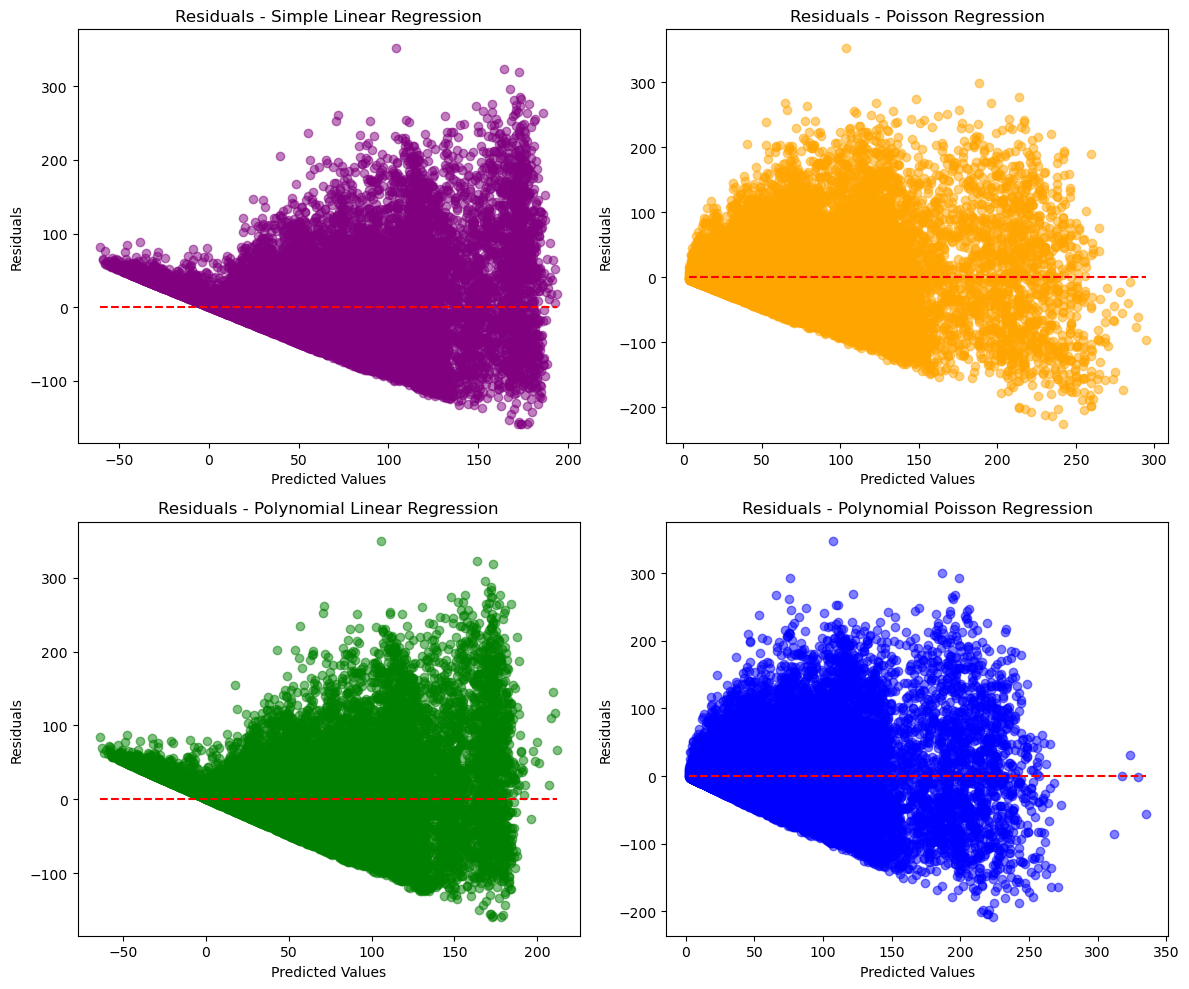

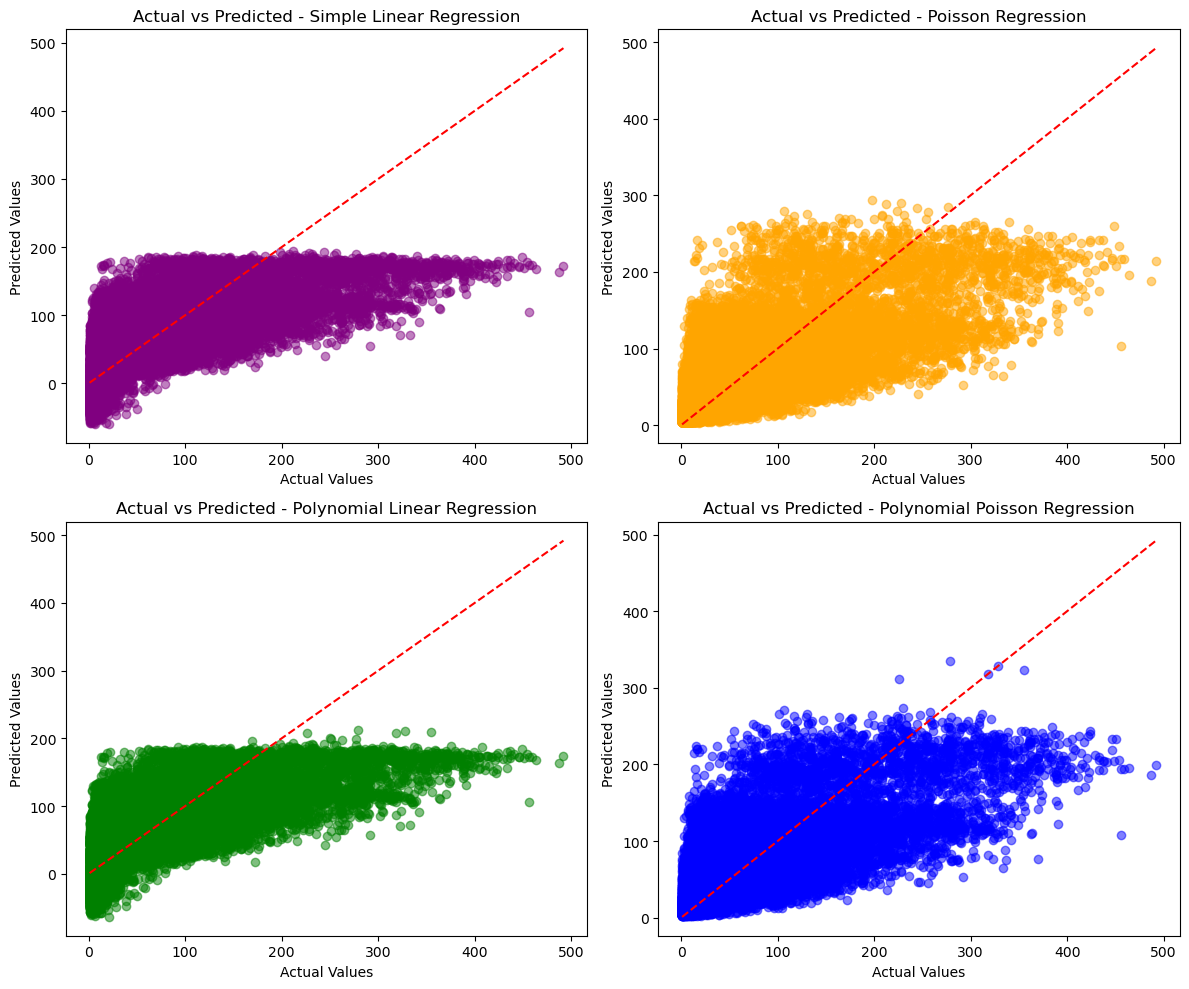

(3248.957437373764, 2911.749566282579, 3231.0891737650677, 2806.23238920612)

In [26]:
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error

# Fitting the four models again (for residual analysis and predictions)
# 1. Simple Linear Regression
linear_model = sm.OLS(y, X.astype(float)).fit()
linear_residuals = y - linear_model.predict(X)
linear_predictions = linear_model.predict(X)
linear_mse = mean_squared_error(y, linear_predictions)

X=X.astype('int64')
# 2. Poisson Regression
poisson_model = Poisson(y, X.astype('int64')).fit()
poisson_residuals = y - poisson_model.predict(X)
poisson_predictions = poisson_model.predict(X)
poisson_mse = mean_squared_error(y, poisson_predictions)

# 3. Polynomial Linear Regression
# Create polynomial features
poly = PolynomialFeatures(degree=2, include_bias=False)
X_poly = poly.fit_transform(X_continuous)
X_poly_df = pd.DataFrame(X_poly, columns=poly_feature_names)
X_poly_combined = pd.concat([X_poly_df, rides_data[['hour', 'night_time', 'evening_rush', 'weekend', 'season_Spring', 'season_Summer', 'season_Winter']]], axis=1)
X_poly_combined = sm.add_constant(X_poly_combined)
poly_linear_model = sm.OLS(y, X_poly_combined.astype(float)).fit()
poly_linear_residuals = y - poly_linear_model.predict(X_poly_combined)
poly_linear_predictions = poly_linear_model.predict(X_poly_combined)
poly_linear_mse = mean_squared_error(y, poly_linear_predictions)

X_poly_combined = X_poly_combined.astype('int64')
# 4. Polynomial Poisson Regression
poly_poisson_model = Poisson(y, X_poly_combined).fit()
poly_poisson_residuals = y - poly_poisson_model.predict(X_poly_combined)
poly_poisson_predictions = poly_poisson_model.predict(X_poly_combined)
poly_poisson_mse = mean_squared_error(y, poly_poisson_predictions)

# Plotting residuals for each model
plt.figure(figsize=(12, 10))

# Residuals for Simple Linear Regression
plt.subplot(2, 2, 1)
plt.scatter(linear_predictions, linear_residuals, alpha=0.5, color='purple')
plt.hlines(0, min(linear_predictions), max(linear_predictions), colors='red', linestyles='dashed')
plt.xlabel("Predicted Values")
plt.ylabel("Residuals")
plt.title("Residuals - Simple Linear Regression")

# Residuals for Poisson Regression
plt.subplot(2, 2, 2)
plt.scatter(poisson_predictions, poisson_residuals, alpha=0.5, color='orange')
plt.hlines(0, min(poisson_predictions), max(poisson_predictions), colors='red', linestyles='dashed')
plt.xlabel("Predicted Values")
plt.ylabel("Residuals")
plt.title("Residuals - Poisson Regression")

# Residuals for Polynomial Linear Regression
plt.subplot(2, 2, 3)
plt.scatter(poly_linear_predictions, poly_linear_residuals, alpha=0.5, color='green')
plt.hlines(0, min(poly_linear_predictions), max(poly_linear_predictions), colors='red', linestyles='dashed')
plt.xlabel("Predicted Values")
plt.ylabel("Residuals")
plt.title("Residuals - Polynomial Linear Regression")

# Residuals for Polynomial Poisson Regression
plt.subplot(2, 2, 4)
plt.scatter(poly_poisson_predictions, poly_poisson_residuals, alpha=0.5, color='blue')
plt.hlines(0, min(poly_poisson_predictions), max(poly_poisson_predictions), colors='red', linestyles='dashed')
plt.xlabel("Predicted Values")
plt.ylabel("Residuals")
plt.title("Residuals - Polynomial Poisson Regression")

plt.tight_layout()
plt.show()

# Plotting Actual vs Predicted for each model
plt.figure(figsize=(12, 10))

# Actual vs Predicted - Simple Linear Regression
plt.subplot(2, 2, 1)
plt.scatter(y, linear_predictions, alpha=0.5, color='purple')
plt.plot([min(y), max(y)], [min(y), max(y)], color='red', linestyle='dashed')
plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Actual vs Predicted - Simple Linear Regression")

# Actual vs Predicted - Poisson Regression
plt.subplot(2, 2, 2)
plt.scatter(y, poisson_predictions, alpha=0.5, color='orange')
plt.plot([min(y), max(y)], [min(y), max(y)], color='red', linestyle='dashed')
plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Actual vs Predicted - Poisson Regression")

# Actual vs Predicted - Polynomial Linear Regression
plt.subplot(2, 2, 3)
plt.scatter(y, poly_linear_predictions, alpha=0.5, color='green')
plt.plot([min(y), max(y)], [min(y), max(y)], color='red', linestyle='dashed')
plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Actual vs Predicted - Polynomial Linear Regression")

# Actual vs Predicted - Polynomial Poisson Regression
plt.subplot(2, 2, 4)
plt.scatter(y, poly_poisson_predictions, alpha=0.5, color='blue')
plt.plot([min(y), max(y)], [min(y), max(y)], color='red', linestyle='dashed')
plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Actual vs Predicted - Polynomial Poisson Regression")

plt.tight_layout()
plt.show()

# Displaying Mean Squared Errors for each model
linear_mse, poisson_mse, poly_linear_mse, poly_poisson_mse


As can be seen from the plots and the MSE values in the end, the Poisson models perform superior to Linear models.
The lowest MSE value is observed in Polynomial Poisson Regression, followed by Simple Poisson Regression. 
For the polynomial and simple linear regression, the MSE values are significantly higher than Poisson regressions.
Also, the unrealistic and illogical negative ride count predictions can be seen in the Polynomial and Simple Linear regression graphs.
For all these reasons, the best choice seems to be Polynomial Poisson Regression.
To make sure, we decided to analyze QQ plots too, as interpreting them could be more useful.

<Figure size 1000x600 with 0 Axes>

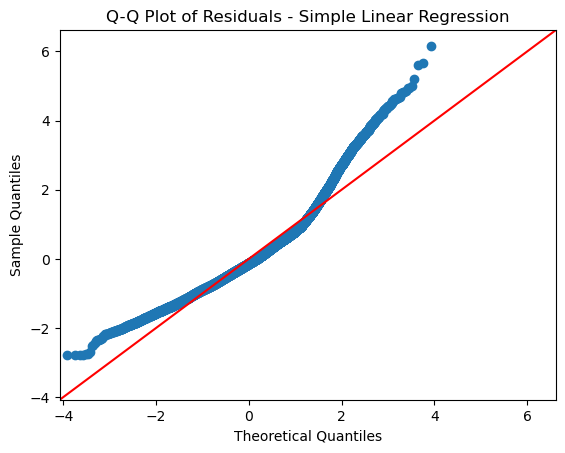

<Figure size 1000x600 with 0 Axes>

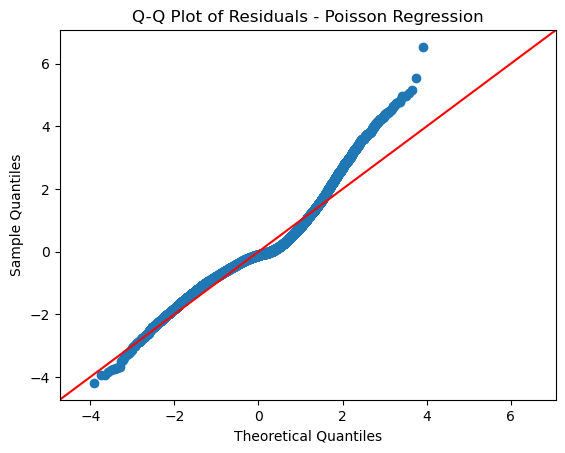

<Figure size 1000x600 with 0 Axes>

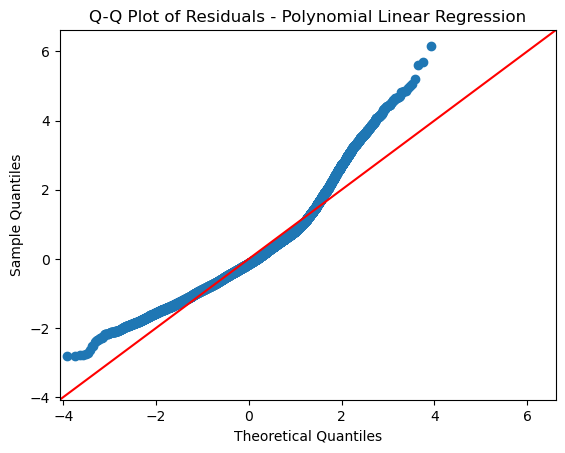

<Figure size 1000x600 with 0 Axes>

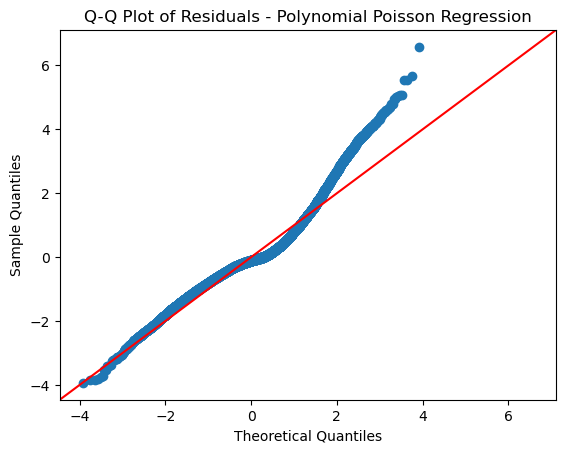

In [27]:
# Ensuring all residuals and predictions are numeric and handling any NaN values

# Converting residuals to numeric and dropping NaNs (if any)
linear_residuals = pd.to_numeric(linear_residuals, errors='coerce').dropna()
poisson_residuals = pd.to_numeric(poisson_residuals, errors='coerce').dropna()
poly_linear_residuals = pd.to_numeric(poly_linear_residuals, errors='coerce').dropna()
poly_poisson_residuals = pd.to_numeric(poly_poisson_residuals, errors='coerce').dropna()

# Re-plotting Q-Q plots for each model's residuals

# 1. Q-Q Plot for Simple Linear Regression Residuals
plt.figure(figsize=(10, 6))
sm.qqplot(linear_residuals, line='45', fit=True)
plt.title("Q-Q Plot of Residuals - Simple Linear Regression")
plt.show()

# 2. Q-Q Plot for Poisson Regression Residuals
plt.figure(figsize=(10, 6))
sm.qqplot(poisson_residuals, line='45', fit=True)
plt.title("Q-Q Plot of Residuals - Poisson Regression")
plt.show()

# 3. Q-Q Plot for Polynomial Linear Regression Residuals
plt.figure(figsize=(10, 6))
sm.qqplot(poly_linear_residuals, line='45', fit=True)
plt.title("Q-Q Plot of Residuals - Polynomial Linear Regression")
plt.show()

# 4. Q-Q Plot for Polynomial Poisson Regression Residuals
plt.figure(figsize=(10, 6))
sm.qqplot(poly_poisson_residuals, line='45', fit=True)
plt.title("Q-Q Plot of Residuals - Polynomial Poisson Regression")
plt.show()


As expected, the Q-Q plots confirmed our evaluations.

Let's interpret each one by one.

Simple Linear Regression: The Q-Q plot deviates significantly from the straight line, especially in the tails, suggesting that residuals are not normally distributed. This indicates that a simple linear regression might not be capturing the underlying distribution well, likely due to the count nature of the response variable.

Poisson Regression: The Q-Q plot still shows deviations from the line, yet there is an improvement compared to the simple linear regression. Poisson regression aligns better with the count data, but it still has non-normal residuals.

Polynomial Linear Regression: The plot shows some improvement in the central part of the distribution, aligning more closely with the line. However, there are still noticeable deviations in the tails, indicating that a polynomial linear regression does not fully capture the variability in counts.

Polynomial Poisson Regression: This Q-Q plot has the best alignment with the straight line, especially in the central part of the distribution. There are slight deviations at the extremes, but overall, it indicates a better fit, supporting our claim that the polynomial Poisson model is better suited for modeling count data with nonlinear effects.

These Q-Q plots confirm that the Polynomial Poisson Regression provides the closest fit to the expected residual distribution, aligning well with the count nature of the data and accounting for nonlinear relationships.

## Day 3

In [28]:
# Load the datasets
df_predictivemaintenance = pd.read_csv('predictive_maintenance.csv')
df_predictivemaintenance_train = pd.read_csv('predictive_maintenance_train.csv')
df_predictivemaintenance_test = pd.read_csv('predictive_maintenance_test.csv')


# Display the first five rows
print("First five rows of the full dataset:")
print(df_predictivemaintenance.head())

print("First five rows of the training dataset:")
print(df_predictivemaintenance_train.head())

print("\nFirst five rows of the test dataset:")
print(df_predictivemaintenance_test.head())


First five rows of the full dataset:
   UDI Product ID Type  Air temperature [K]  Process temperature [K]  \
0    1     M14860    M                298.1                    308.6   
1    2     L47181    L                298.2                    308.7   
2    3     L47182    L                298.1                    308.5   
3    4     L47183    L                298.2                    308.6   
4    5     L47184    L                298.2                    308.7   

   Rotational speed [rpm]  Torque [Nm]  Tool wear [min]  Target Failure Type  \
0                    1551         42.8                0       0   No Failure   
1                    1408         46.3                3       0   No Failure   
2                    1498         49.4                5       0   No Failure   
3                    1433         39.5                7       0   No Failure   
4                    1408         40.0                9       0   No Failure   

   Monday  
0       0  
1       0  
2       0  
3

In [29]:
# Get basic information about the dataset
data_info = df_predictivemaintenance.info()

# Get summary statistics
summary = df_predictivemaintenance.describe(include='all')

# Calculate number of missing values for each column
missing_values = df_predictivemaintenance.isnull().sum()

# Number of unique values for each column
unique_values = df_predictivemaintenance.nunique()

# Create the overview table
overview_table = pd.DataFrame({
    'Variable': df_predictivemaintenance.columns,
    'Data Type': df_predictivemaintenance.dtypes,
    'Unique Values': unique_values,
    'Missing Values': missing_values,
    'Description': ''  # Fill in descriptions manually if needed
})

print("\nOverview of Variables:")
print(overview_table)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Target                   10000 non-null  int64  
 9   Failure Type             10000 non-null  object 
 10  Monday                   10000 non-null  int64  
dtypes: float64(3), int64(5), object(3)
memory usage: 859.5+ KB

Overview of Variables:
                                        Variable Data Type  Unique Values  \
UDI                      

In [30]:
# Get basic information about the training dataset
data_info = df_predictivemaintenance_train.info()

# Get summary statistics
summary = df_predictivemaintenance_train.describe(include='all')

# Calculate number of missing values for each column
missing_values = df_predictivemaintenance_train.isnull().sum()

# Number of unique values for each column
unique_values = df_predictivemaintenance_train.nunique()

# Create the overview table
overview_table_train = pd.DataFrame({
    'Variable': df_predictivemaintenance_train.columns,
    'Data Type': df_predictivemaintenance_train.dtypes,
    'Unique Values': unique_values,
    'Missing Values': missing_values,
    'Description': ''  # Fill in descriptions manually if needed
})

print("\nOverview of Variables:")
print(overview_table_train)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7500 entries, 0 to 7499
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      7500 non-null   int64  
 1   Product ID               7500 non-null   object 
 2   Type                     7500 non-null   object 
 3   Air temperature [K]      7500 non-null   float64
 4   Process temperature [K]  7500 non-null   float64
 5   Rotational speed [rpm]   7500 non-null   int64  
 6   Torque [Nm]              7500 non-null   float64
 7   Tool wear [min]          7500 non-null   int64  
 8   Target                   7500 non-null   int64  
 9   Failure Type             7500 non-null   object 
 10  Monday                   7500 non-null   int64  
dtypes: float64(3), int64(5), object(3)
memory usage: 644.7+ KB

Overview of Variables:
                                        Variable Data Type  Unique Values  \
UDI                       

In [31]:
# Get basic information about the test dataset
data_info = df_predictivemaintenance_test.info()

# Get summary statistics
summary = df_predictivemaintenance_test.describe(include='all')

# Calculate number of missing values for each column
missing_values = df_predictivemaintenance_test.isnull().sum()

# Number of unique values for each column
unique_values = df_predictivemaintenance_test.nunique()

# Create the overview table
overview_table_test = pd.DataFrame({
    'Variable': df_predictivemaintenance_test.columns,
    'Data Type': df_predictivemaintenance_test.dtypes,
    'Unique Values': unique_values,
    'Missing Values': missing_values,
    'Description': ''  # Fill in descriptions manually if needed
})

print("\nOverview of Variables:")
print(overview_table_test)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      2500 non-null   int64  
 1   Product ID               2500 non-null   object 
 2   Type                     2500 non-null   object 
 3   Air temperature [K]      2500 non-null   float64
 4   Process temperature [K]  2500 non-null   float64
 5   Rotational speed [rpm]   2500 non-null   int64  
 6   Torque [Nm]              2500 non-null   float64
 7   Tool wear [min]          2500 non-null   int64  
 8   Target                   2500 non-null   int64  
 9   Failure Type             2500 non-null   object 
 10  Monday                   2500 non-null   int64  
dtypes: float64(3), int64(5), object(3)
memory usage: 215.0+ KB

Overview of Variables:
                                        Variable Data Type  Unique Values  \
UDI                       

### a) Base Model: Logistic Regression

In [32]:
# One-hot encode the 'Type' column to ensure all dummy variables are created
df_predictivemaintenance_train_d = pd.get_dummies(df_predictivemaintenance_train, columns=['Type'], drop_first=True)
df_predictivemaintenance_test_d = pd.get_dummies(df_predictivemaintenance_test, columns=['Type'], drop_first=True)

# Define features (X) and target (y) for training data
X_train = df_predictivemaintenance_train_d[['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 
                                            'Torque [Nm]', 'Tool wear [min]', 'Monday', 'Type_L', 'Type_M']]
# Add constant term for the intercept
X_train = sm.add_constant(X_train)
y_train = df_predictivemaintenance_train_d['Target']  # Define target variable

# Convert boolean columns to integers (0s and 1s)
X_train = X_train.astype({'Type_L': 'int', 'Type_M': 'int', 'Type_M': 'int'})

# Fit the logistic regression model
model = sm.Logit(y_train, X_train)
results = model.fit()

# Display the regression summary
print(results.summary())

Optimization terminated successfully.
         Current function value: 0.076980
         Iterations 10
                           Logit Regression Results                           
Dep. Variable:                 Target   No. Observations:                 7500
Model:                          Logit   Df Residuals:                     7491
Method:                           MLE   Df Model:                            8
Date:                Tue, 12 Nov 2024   Pseudo R-squ.:                  0.4889
Time:                        18:33:20   Log-Likelihood:                -577.35
converged:                       True   LL-Null:                       -1129.6
Covariance Type:            nonrobust   LLR p-value:                4.280e-233
                              coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------
const                     -65.4696     19.017     -3.443      0.001    -102.743  

Results interpretation: The Pseudo-R-Squared indicates that approximately 48.89% of the variability in the target variable is explained by the model, suggesting a good fit but also room for improvement.

P-Values:
A p-value less than 0.05 typically indicates that the predictor is statistically significant. In your results:
Variables like Air temperature [K], Process temperature [K], Rotational speed [rpm], Torque [Nm], Tool wear [min], and Monday all have p-values of 0.000, suggesting that they are highly significant.
However, Type_L and Type_M have p-values greater than 0.05 (0.426 and 0.562, respectively), indicating that these variables may not significantly contribute to the model.

### Code imported for confusion matrix

In [33]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

def make_confusion_matrix(cf,
                          group_names=None,
                          categories='auto',
                          count=True,
                          percent=True,
                          cbar=True,
                          xyticks=True,
                          xyplotlabels=True,
                          sum_stats=True,
                          figsize=None,
                          cmap='Blues',
                          title=None):
    '''
    This function will make a pretty plot of an sklearn Confusion Matrix cm using a Seaborn heatmap visualization.
    Arguments
    ---------
    cf:            confusion matrix to be passed in
    group_names:   List of strings that represent the labels row by row to be shown in each square.
    categories:    List of strings containing the categories to be displayed on the x,y axis. Default is 'auto'
    count:         If True, show the raw number in the confusion matrix. Default is True.
    normalize:     If True, show the proportions for each category. Default is True.
    cbar:          If True, show the color bar. The cbar values are based off the values in the confusion matrix.
                   Default is True.
    xyticks:       If True, show x and y ticks. Default is True.
    xyplotlabels:  If True, show 'True Label' and 'Predicted Label' on the figure. Default is True.
    sum_stats:     If True, display summary statistics below the figure. Default is True.
    figsize:       Tuple representing the figure size. Default will be the matplotlib rcParams value.
    cmap:          Colormap of the values displayed from matplotlib.pyplot.cm. Default is 'Blues'
                   See http://matplotlib.org/examples/color/colormaps_reference.html
                   
    title:         Title for the heatmap. Default is None.
    '''


    # CODE TO GENERATE TEXT INSIDE EACH SQUARE
    blanks = ['' for i in range(cf.size)]

    if group_names and len(group_names)==cf.size:
        group_labels = ["{}\n".format(value) for value in group_names]
    else:
        group_labels = blanks

    if count:
        group_counts = ["{0:0.0f}\n".format(value) for value in cf.flatten()]
    else:
        group_counts = blanks

    if percent:
        group_percentages = ["{0:.2%}".format(value) for value in cf.flatten()/np.sum(cf)]
    else:
        group_percentages = blanks

    box_labels = [f"{v1}{v2}{v3}".strip() for v1, v2, v3 in zip(group_labels,group_counts,group_percentages)]
    box_labels = np.asarray(box_labels).reshape(cf.shape[0],cf.shape[1])


    # CODE TO GENERATE SUMMARY STATISTICS & TEXT FOR SUMMARY STATS
    if sum_stats:
        #Accuracy is sum of diagonal divided by total observations
        accuracy  = np.trace(cf) / float(np.sum(cf))

        #if it is a binary confusion matrix, show some more stats
        if len(cf)==2:
            #Metrics for Binary Confusion Matrices
            precision = cf[1,1] / sum(cf[:,1])
            recall    = cf[1,1] / sum(cf[1,:])
            f1_score  = 2*precision*recall / (precision + recall)
            stats_text = "\n\nAccuracy={:0.3f}\nPrecision={:0.3f}\nRecall={:0.3f}\nF1 Score={:0.3f}".format(
                accuracy,precision,recall,f1_score)
        else:
            stats_text = "\n\nAccuracy={:0.3f}".format(accuracy)
    else:
        stats_text = ""


    # SET FIGURE PARAMETERS ACCORDING TO OTHER ARGUMENTS
    if figsize==None:
        #Get default figure size if not set
        figsize = plt.rcParams.get('figure.figsize')

    if xyticks==False:
        #Do not show categories if xyticks is False
        categories=False


    # MAKE THE HEATMAP VISUALIZATION
    plt.figure(figsize=figsize)
    sns.heatmap(cf,annot=box_labels,fmt="",cmap=cmap,cbar=cbar,xticklabels=categories,yticklabels=categories)

    if xyplotlabels:
        plt.ylabel('True label')
        plt.xlabel('Predicted label' + stats_text)
    else:
        plt.xlabel(stats_text)
    
    if title:
        plt.title(title)

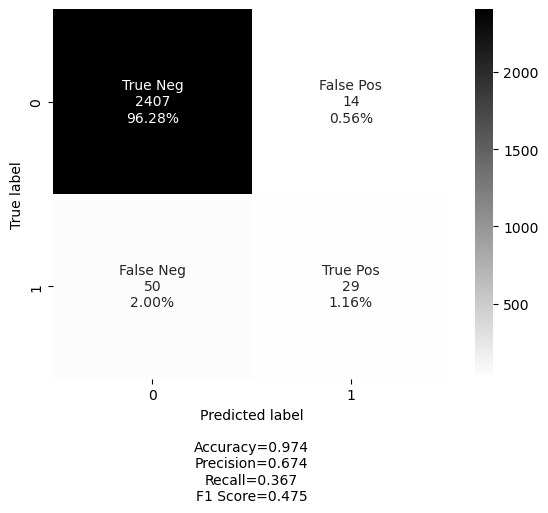

In [34]:
# Now, for the test set:
df_predictivemaintenance_test_d = pd.get_dummies(df_predictivemaintenance_test, columns=['Type'], drop_first=True)

# Define features for test data
X_test = df_predictivemaintenance_test_d[['Air temperature [K]', 'Process temperature [K]', 
                                            'Rotational speed [rpm]', 'Torque [Nm]', 
                                            'Tool wear [min]', 'Monday', 'Type_L', 'Type_M']]

# Define target variable for test data
y_test = df_predictivemaintenance_test_d['Target']  # Extract the target variable

# Add constant term for the intercept in the test data
X_test = sm.add_constant(X_test)

# Convert boolean columns to integers (0s and 1s)
X_test = X_test.astype({'Type_L': 'int', 'Type_M': 'int'})

# Now make predictions on the test data
y_pred = results.predict(X_test)

# Convert predicted probabilities to binary outcomes (for instance, using a threshold of 0.5)
y_pred_binary = (y_pred > 0.5).astype(int)

cf_matrix = confusion_matrix(y_test, y_pred_binary)

labels = ['True Neg','False Pos','False Neg','True Pos']
categories = ['0', '1']
make_confusion_matrix(cf_matrix, group_names=labels, categories=categories, cmap='binary')

Accuracy (97.4%): This indicates that 97.4% of the predictions were correct. However, this can be misleading, especially in imbalanced datasets, where the model might simply be predicting the majority class.
Precision (67.4%): This measures the accuracy of positive predictions. It indicates that when your model predicts the positive class (1), it is correct 67.4% of the time.
Recall (36.7%): This metric shows how well the model identifies actual positives. A recall of 36.7% means that only about one-third of the actual positive cases are being correctly identified by the model.

In [35]:
# Check the distribution of actual values
print("Actual values (y_test):")
print(y_test.value_counts())

# Check the distribution of predicted values
print("\nPredicted values (y_pred_binary):")
print(pd.Series(y_pred_binary).value_counts())

Actual values (y_test):
Target
0    2421
1      79
Name: count, dtype: int64

Predicted values (y_pred_binary):
0    2457
1      43
Name: count, dtype: int64


The actual values (y_test) reveal a significant imbalance in the dataset, with 2421 instances classified as class 0 (the negative class) compared to only 79 instances of class 1 (the positive class). This disparity is mirrored in the predicted values (y_pred_binary), where the model predicts 2457 instances for class 0 and only 43 for class 1, further highlighting the model's tendency to favor the majority class in its predictions. Such imbalances can affect the model's performance, particularly in achieving a higher recall for the minority class.

As we have a highly imbalanced data set, in order to improve our model we have to assign different weights to the two classes.

### Model with balanced weights

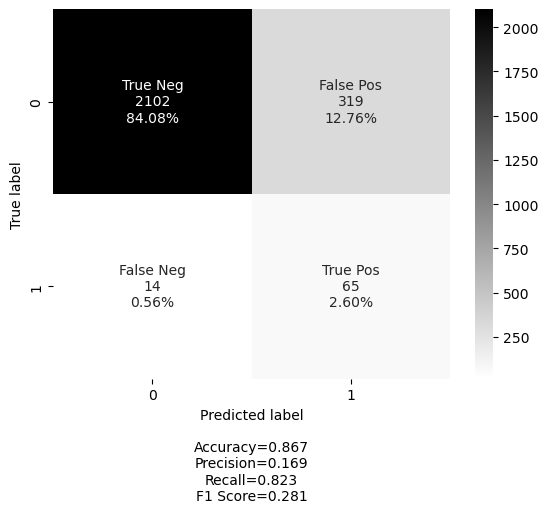

In [36]:
# One-hot encode the 'Type' column to ensure all dummy variables are created
df_predictivemaintenance_train_d = pd.get_dummies(df_predictivemaintenance_train, columns=['Type'], drop_first=True)
df_predictivemaintenance_test_d = pd.get_dummies(df_predictivemaintenance_test, columns=['Type'], drop_first=True)

# Define features (X) and target (y) for training data
X_train = df_predictivemaintenance_train_d[['Air temperature [K]', 'Process temperature [K]', 
                                            'Rotational speed [rpm]', 'Torque [Nm]', 
                                            'Tool wear [min]', 'Monday','Type_L', 'Type_M']]
y_train = df_predictivemaintenance_train_d['Target']  # Define target variable

# Scale the features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

# Initialize and fit the logistic regression model with class weights
model = LogisticRegression(class_weight='balanced')
model.fit(X_train_scaled, y_train)

# Define features (X) for the test data, ensuring it matches the training data's columns
X_test = df_predictivemaintenance_test_d[['Air temperature [K]', 'Process temperature [K]', 
                                            'Rotational speed [rpm]', 'Torque [Nm]', 
                                            'Tool wear [min]', 'Monday','Type_L', 'Type_M']]
y_test = df_predictivemaintenance_test_d['Target']  # Define target variable for test set

# Scale the test set features using the same scaler fitted on the training set
X_test_scaled = scaler.transform(X_test)

# Make predictions on the test set
y_test_pred = model.predict(X_test_scaled)

cf_matrix = confusion_matrix(y_test, y_test_pred)

labels = ['True Neg','False Pos','False Neg','True Pos']
categories = ['0', '1']
make_confusion_matrix(cf_matrix, group_names=labels, categories=categories, cmap='binary')

We can see that our model now puts a higher weight on class 1 (faulty parts) which is why the number of (true and false) positives and hence recall has increased drastically. Due to this increase the model decreases in accuracy and precision which has to be corrected in the next step.

Our initial model suffered from poor recall on the minority class (class 1), which indicates the model struggled to correctly identify positive cases. To address this, we applied the "balanced" class weight setting. This weighting scheme compensates for the imbalanced data distribution by giving more emphasis to class 1, resulting in a higher recall for that class. However, as expected, the increase in recall led to a trade-off with precision and overall accuracy, as the model now classifies more instances as positive, which increases false positives.

To further refine this balance, we are adjusting the decision threshold. Lowering the threshold effectively helps the model favor class 1, increasing recall, while a higher threshold counteracts this by requiring a higher probability before classifying a case as positive, thus aiming to reduce false positives and improve precision and accuracy. This combination of class weighting and threshold adjustment allows us to achieve a more balanced performance, aligning better with our objective to capture positive cases without overly compromising accuracy or precision.

That is why we will increase the decision threshold in the next model.

### Model with balanced weights and higher decision threshold

              precision    recall  f1-score   support

           0       0.99      0.95      0.97      2421
           1       0.31      0.67      0.42        79

    accuracy                           0.94      2500
   macro avg       0.65      0.81      0.70      2500
weighted avg       0.97      0.94      0.95      2500



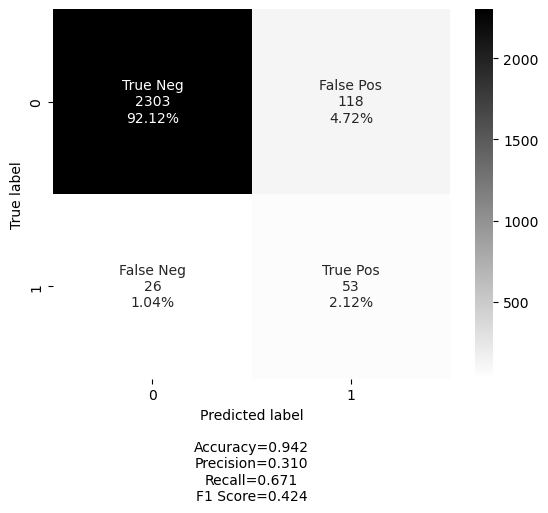

In [37]:
# One-hot encode the 'Type' column
df_predictivemaintenance_train_d = pd.get_dummies(df_predictivemaintenance_train, columns=['Type'], drop_first=True)
df_predictivemaintenance_test_d = pd.get_dummies(df_predictivemaintenance_test, columns=['Type'], drop_first=True)

# Define features (X) and target (y) for training data
X_train = df_predictivemaintenance_train_d[['Air temperature [K]', 'Process temperature [K]', 
                                            'Rotational speed [rpm]', 'Torque [Nm]', 
                                            'Tool wear [min]', 'Monday', 'Type_L', 'Type_M']]
y_train = df_predictivemaintenance_train_d['Target']

# Scale the features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

# Initialize and fit the logistic regression model with class weights
model = LogisticRegression(class_weight='balanced')
model.fit(X_train_scaled, y_train)

# Define features (X) for the test data
X_test = df_predictivemaintenance_test_d[['Air temperature [K]', 'Process temperature [K]', 
                                          'Rotational speed [rpm]', 'Torque [Nm]', 
                                          'Tool wear [min]', 'Monday', 'Type_L', 'Type_M']]
y_test = df_predictivemaintenance_test_d['Target']

# Scale the test set features
X_test_scaled = scaler.transform(X_test)

# Make predictions with a custom threshold
y_test_proba = model.predict_proba(X_test_scaled)[:, 1]  # Get probabilities for class 1
threshold = 0.79  # Set custom threshold
y_test_pred_custom_threshold = (y_test_proba >= threshold).astype(int)

# Evaluate the model on the test set with the custom threshold
print(classification_report(y_test, y_test_pred_custom_threshold))

# Confusion matrix with custom threshold
cf_matrix = confusion_matrix(y_test, y_test_pred_custom_threshold)

# Plot the confusion matrix
labels = ['True Neg','False Pos','False Neg','True Pos']
categories = ['0', '1']
make_confusion_matrix(cf_matrix, group_names=labels, categories=categories, cmap='binary')

This model is our final solution as it achieves a higher accuracy (94,2%), Precision (31%), and Recall (67,1%) than the guru's benchmark model. We achieved this solution with a decision threshold of 0.79.

### b) Interpretation of the final model

In [38]:
# View coefficients for the final model with balanced weights
feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Coefficient': model.coef_[0]
}).sort_values(by='Coefficient', ascending=False)

print(feature_importance)


                   Feature  Coefficient
3              Torque [Nm]     2.552375
2   Rotational speed [rpm]     1.787417
0      Air temperature [K]     1.710247
5                   Monday     1.182440
4          Tool wear [min]     1.038528
6                   Type_L     0.228588
7                   Type_M     0.114402
1  Process temperature [K]    -1.153887


From our base model we have already established that only the variables Air temperature [K], Process temperature [K], Rotational speed [rpm], Torque [Nm], Tool wear [min], and Monday are significant due to their low p-value.

Considering the coefficients of the final model with adjusted class weight and decision threshold we can observe that Torque, Rotational speed, and Air temperature are the most important predictors of failure, with higher values leading to an increased likelihood of failure. Process temperature, with a negative coefficient, suggests that higher temperatures may reduce the likelihood of failure in this case. Tool wear also increases failure likelihood, but to a lesser extent. Additionally, failures are more likely on Mondays, possibly indicating operational or maintenance patterns.

## Day 4

In [43]:
from sklearn.linear_model import Lasso
import numpy as np

# Preparing the data
# Removing any non-numeric columns and handling NaNs if necessary
X_lasso = rides_data.select_dtypes(include=[np.number]).drop(columns=['ride_count']).fillna(0)
y_lasso = rides_data['ride_count']

# Standardizing features to ensure comparability across regularization
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_lasso)

# Defining lambda values (alpha parameter in sklearn's Lasso)
lambdas = [0, 1, 3]

# Running LASSO for each lambda
lasso_results = {}
for lmbd in lambdas:
    lasso = Lasso(alpha=lmbd)
    lasso.fit(X_scaled, y_lasso)
    lasso_results[lmbd] = lasso.coef_

# Creating a DataFrame to display the results
lasso_df = pd.DataFrame(lasso_results, index=X_lasso.columns)
lasso_df.columns = [f'Lambda = {lmbd}' for lmbd in lambdas]



C:\Users\ASUS\anaconda3\Lib\site-packages\sklearn\base.py:1151: UserWarning: With alpha=0, this algorithm does not converge well. You are advised to use the LinearRegression estimator
  return fit_method(estimator, *args, **kwargs)
C:\Users\ASUS\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:628: UserWarning: Coordinate descent with no regularization may lead to unexpected results and is discouraged.
  model = cd_fast.enet_coordinate_descent(
C:\Users\ASUS\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:628: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.292e+07, tolerance: 1.323e+04 Linear regression models with null weight for the l1 regularization term are more efficiently fitted using one of the solvers implemented in sklearn.linear_model.Ridge/RidgeCV instead.
  model = cd_fast.enet_coordinate_d

In [44]:
from sklearn.linear_model import LinearRegression

# Running Linear Regression for lambda = 0
linear_reg = LinearRegression()
linear_reg.fit(X_scaled, y_lasso)
coefficients_lambda_0 = linear_reg.coef_

# Running LASSO for lambda = 1 and lambda = 3 with increased iterations
lasso_results_summary_fixed = {}
for lmbd in [1, 3]:
    lasso = Lasso(alpha=lmbd, max_iter=10000)  # Increasing max iterations to help with convergence
    lasso.fit(X_scaled, y_lasso)
    lasso_results_summary_fixed[lmbd] = lasso.coef_

# Creating a summary DataFrame with Linear Regression and LASSO results
summary_fixed = pd.DataFrame({
    'Linear Regression (Lambda = 0)': coefficients_lambda_0,
    'LASSO (Lambda = 1)': lasso_results_summary_fixed[1],
    'LASSO (Lambda = 3)': lasso_results_summary_fixed[3]
}, index=X_lasso.columns)

# Filtering to show only coefficients that were selected (non-zero) by at least one model
selected_features_summary_fixed = summary_fixed[(summary_fixed != 0).any(axis=1)]

summary_fixed

,Linear Regression (Lambda = 0),LASSO (Lambda = 1),LASSO (Lambda = 3)
temperature_max,15.533351,0.000000,0.000000
temperature_min,-39.414716,0.000000,0.000000
temperature_avg,85.647921,17.696379,16.728940
feels_like_max,-40.241527,0.000000,0.000000
feels_like_min,31.335142,7.804825,4.791828
feels_like_avg,-56.192459,0.000000,0.000000
dew_point,35.703004,0.000000,0.000000
humidity_percent,-21.084253,-5.047982,-0.679519
precipitation_amount,-0.647441,-0.003580,-0.000000
precipitation_probability,2.801455,0.000000,0.000000


## Day 5

In [45]:
# Import necessary libraries
import pandas as pd

# Load the auction data
data_path = 'auction_data.csv'
auction_data = pd.read_csv(data_path)

# Display the first few rows to understand the structure of the dataset
auction_data.head()


,Valuation,Bid 2-bidder auction,Bid 4-bidder auction
0,5.7,4.7,5.0
1,3.3,1.1,2.5
2,6.0,4.0,5.9
3,8.1,5.5,7.6
4,6.9,6.0,3.0


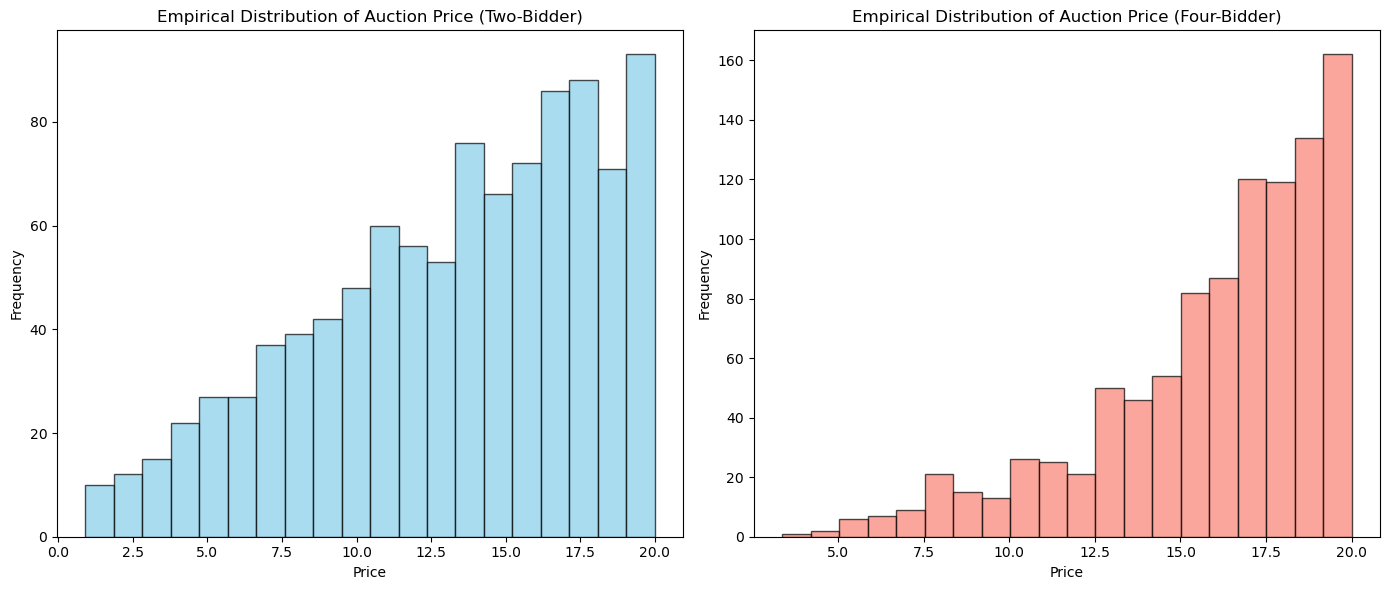

In [47]:
import numpy as np
import matplotlib.pyplot as plt

# Creating dummy auction data based on the user's description
# Assuming there are 10,000 rows of valuation and corresponding bid data
np.random.seed(42)
auction_data = pd.DataFrame({
    'Valuation': np.random.uniform(0, 20, 10000),
    'Bid_2_bidder': np.random.uniform(0, 20, 10000),
    'Bid_4_bidder': np.random.uniform(0, 20, 10000)
})

# Simulate 1,000 two-bidder auctions
two_bidder_prices = []
for _ in range(1000):
    sampled_bids = auction_data['Bid_2_bidder'].sample(2)
    winning_price = sampled_bids.max()
    two_bidder_prices.append(winning_price)

# Simulate 1,000 four-bidder auctions
four_bidder_prices = []
for _ in range(1000):
    sampled_bids = auction_data['Bid_4_bidder'].sample(4)
    winning_price = sampled_bids.max()
    four_bidder_prices.append(winning_price)

# Plotting the empirical distributions
plt.figure(figsize=(14, 6))

# Histogram for two-bidder auctions
plt.subplot(1, 2, 1)
plt.hist(two_bidder_prices, bins=20, color='skyblue', edgecolor='black', alpha=0.7)
plt.title('Empirical Distribution of Auction Price (Two-Bidder)')
plt.xlabel('Price')
plt.ylabel('Frequency')

# Histogram for four-bidder auctions
plt.subplot(1, 2, 2)
plt.hist(four_bidder_prices, bins=20, color='salmon', edgecolor='black', alpha=0.7)
plt.title('Empirical Distribution of Auction Price (Four-Bidder)')
plt.xlabel('Price')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()


In [48]:
# Calculating the probability that the price is above 8 in each type of auction

# Convert the lists of winning prices into numpy arrays for easier calculations
two_bidder_prices = np.array(two_bidder_prices)
four_bidder_prices = np.array(four_bidder_prices)

# Calculate the probability that the price is above 8
probability_two_bidder_above_8 = np.mean(two_bidder_prices > 8)
probability_four_bidder_above_8 = np.mean(four_bidder_prices > 8)

probability_two_bidder_above_8, probability_four_bidder_above_8


(0.832, 0.966)

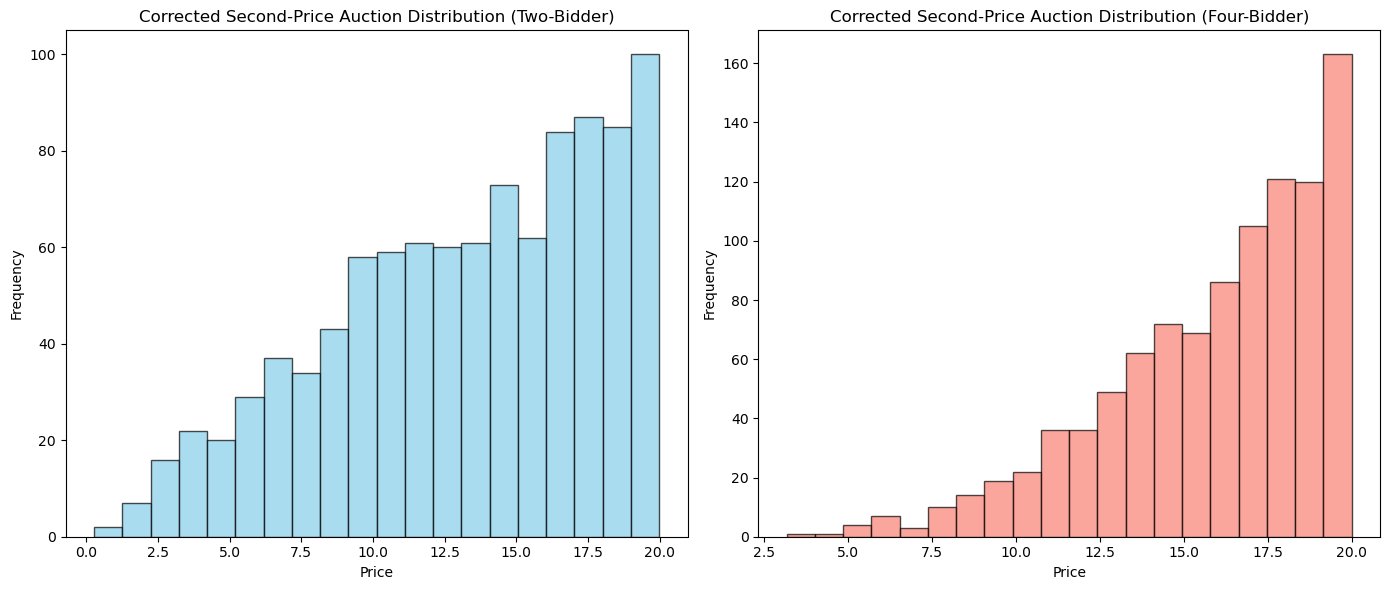

In [57]:
# Simulate 1,000 two-bidder second-price auctions (finding the second-highest bid)
two_bidder_second_prices_corrected = []
for _ in range(1000):
    sampled_bids = auction_data['Bid_2_bidder'].sample(2)
    second_price = sampled_bids.nlargest(2).iloc[-2]  
    two_bidder_second_prices_corrected.append(second_price)

# Simulate 1,000 four-bidder second-price auctions (finding the second-highest bid)
four_bidder_second_prices_corrected = []
for _ in range(1000):
    sampled_bids = auction_data['Bid_4_bidder'].sample(4)
    second_price = sampled_bids.nlargest(2).iloc[-2] 
    four_bidder_second_prices_corrected.append(second_price)

# Plotting the corrected empirical distributions for second-price auctions
plt.figure(figsize=(14, 6))

# Histogram for corrected two-bidder second-price auctions
plt.subplot(1, 2, 1)
plt.hist(two_bidder_second_prices_corrected, bins=20, color='skyblue', edgecolor='black', alpha=0.7)
plt.title('Corrected Second-Price Auction Distribution (Two-Bidder)')
plt.xlabel('Price')
plt.ylabel('Frequency')

# Histogram for corrected four-bidder second-price auctions
plt.subplot(1, 2, 2)
plt.hist(four_bidder_second_prices_corrected, bins=20, color='salmon', edgecolor='black', alpha=0.7)
plt.title('Corrected Second-Price Auction Distribution (Four-Bidder)')
plt.xlabel('Price')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()


In [58]:
# First, we need to calculate the expected price and variance for each type of auction

# First-Price Auctions
# Two-Bidder Auction (First-Price)
two_bidder_first_prices = np.array(two_bidder_prices)
expected_price_two_bidder_first = np.mean(two_bidder_first_prices)
variance_two_bidder_first = np.var(two_bidder_first_prices)

# Four-Bidder Auction (First-Price)
four_bidder_first_prices = np.array(four_bidder_prices)
expected_price_four_bidder_first = np.mean(four_bidder_first_prices)
variance_four_bidder_first = np.var(four_bidder_first_prices)

# Second-Price Auctions (Corrected)
# Two-Bidder Auction (Second-Price)
two_bidder_second_prices = np.array(two_bidder_second_prices_corrected)
expected_price_two_bidder_second = np.mean(two_bidder_second_prices)
variance_two_bidder_second = np.var(two_bidder_second_prices)

# Four-Bidder Auction (Second-Price)
four_bidder_second_prices = np.array(four_bidder_second_prices_corrected)
expected_price_four_bidder_second = np.mean(four_bidder_second_prices)
variance_four_bidder_second = np.var(four_bidder_second_prices)

# Summary of Expected Prices and Variances
summary = {
    'Auction Type': ['Two-Bidder First-Price', 'Two-Bidder Second-Price', 'Four-Bidder First-Price', 'Four-Bidder Second-Price'],
    'Expected Price': [expected_price_two_bidder_first, expected_price_two_bidder_second, expected_price_four_bidder_first, expected_price_four_bidder_second],
    'Variance': [variance_two_bidder_first, variance_two_bidder_second, variance_four_bidder_first, variance_four_bidder_second]
}

summary_df = pd.DataFrame(summary)

summary_df

,Auction Type,Expected Price,Variance
0,Two-Bidder First-Price,13.200113,22.528834
1,Two-Bidder Second-Price,13.233303,22.527553
2,Four-Bidder First-Price,16.027153,11.347210
3,Four-Bidder Second-Price,15.922926,10.672062


## Day 6

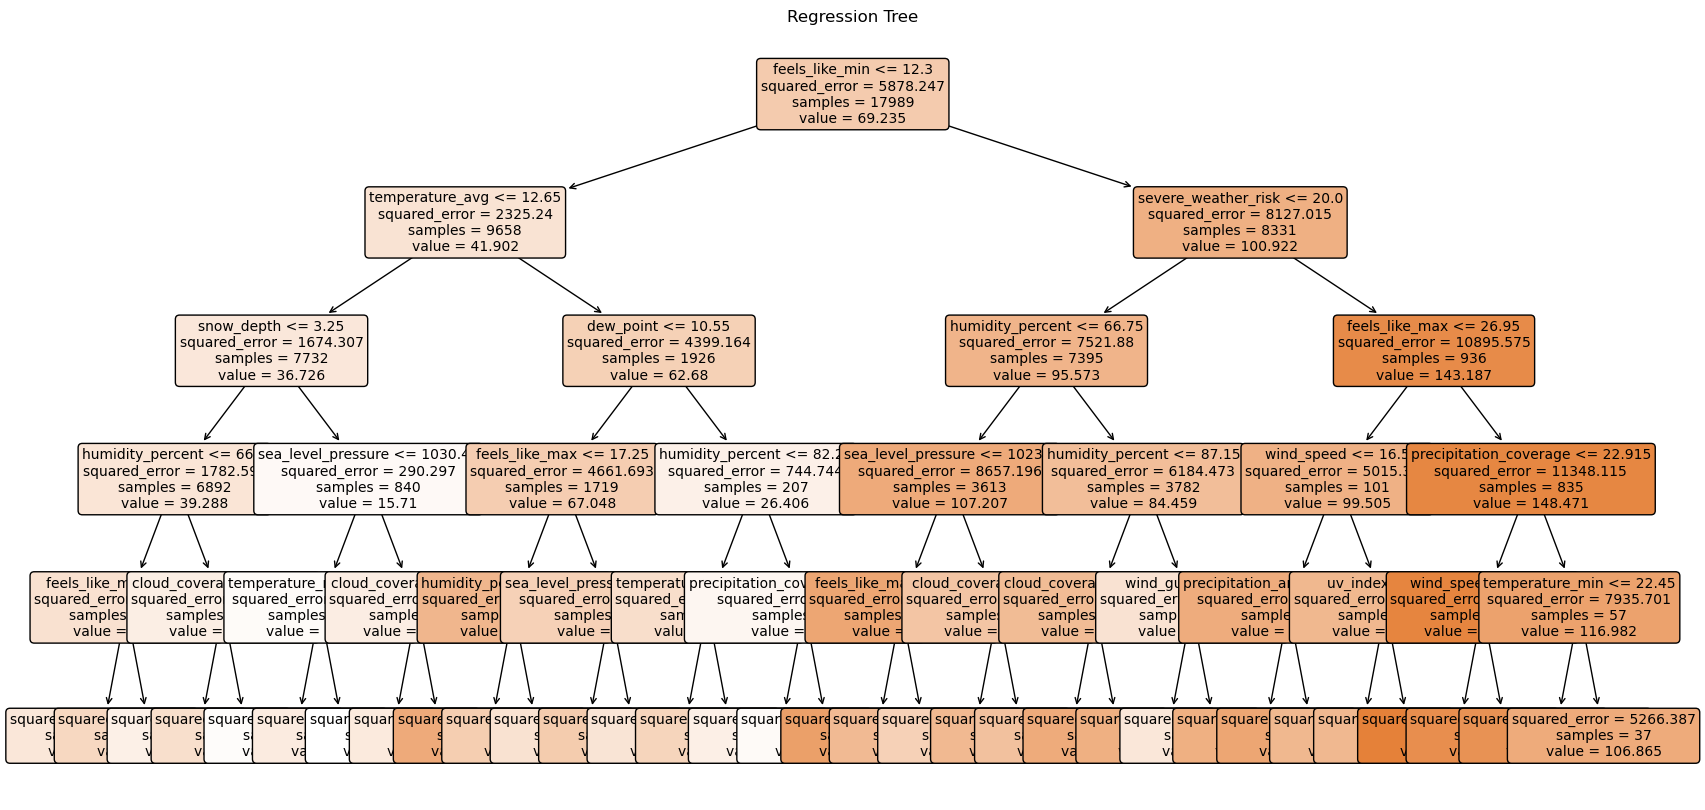

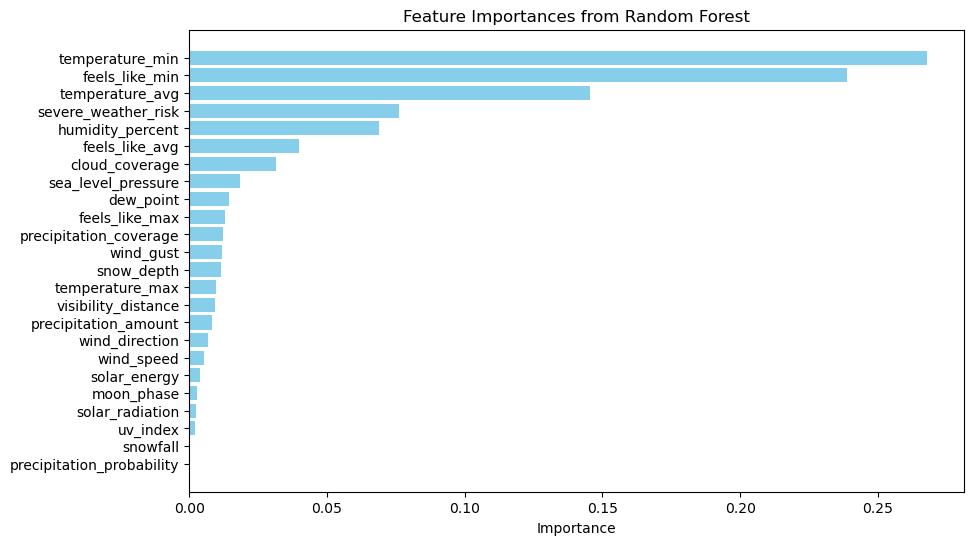

Feature Importances from Regression Tree and Random Forest:
                      Feature  Regression Tree Importance  \
1             temperature_min                1.397823e-03   
4              feels_like_min                6.618521e-01   
2             temperature_avg                4.312885e-02   
22        severe_weather_risk                7.821550e-02   
7            humidity_percent                7.856424e-02   
5              feels_like_avg                0.000000e+00   
17             cloud_coverage                2.635924e-02   
16         sea_level_pressure                3.276388e-02   
6                   dew_point                1.267227e-02   
3              feels_like_max                4.004023e-02   
10     precipitation_coverage                2.757987e-03   
13                  wind_gust                3.143094e-03   
12                 snow_depth                1.728476e-02   
0             temperature_max                0.000000e+00   
18        visibility_dist

In [67]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler

# Load the rides dataset
data_path = 'Rides_daily.csv'
rides_data = pd.read_csv(data_path)

# Prepare the data
# Assuming ride_count is the target variable and other numerical columns are predictors
X = rides_data.select_dtypes(include=[np.number]).drop(columns=['ride_count'])
y = rides_data['ride_count']

# Handle missing values by imputing with the median value of each feature
X_imputed = X.fillna(X.median())

# Split the data into training and testing sets for validation
X_train, X_test, y_train, y_test = train_test_split(X_imputed, y, test_size=0.2, random_state=42)

# Fit a Regression Tree on the entire dataset
reg_tree = DecisionTreeRegressor(max_depth=5, random_state=42)  # Limiting max depth to control complexity
reg_tree.fit(X_train, y_train)

# Plotting the regression tree for visualization
plt.figure(figsize=(20, 10))
plot_tree(reg_tree, feature_names=X.columns.tolist(), filled=True, rounded=True, fontsize=10)
plt.title("Regression Tree")
plt.show()

# Fit a Random Forest Model on the entire dataset
rf_model = RandomForestRegressor(n_estimators=100, max_depth=5, random_state=42)
rf_model.fit(X_train, y_train)

# Extracting feature importances from both models
tree_feature_importances = reg_tree.feature_importances_
rf_feature_importances = rf_model.feature_importances_

# Creating a DataFrame to compare feature importances
feature_importance_df = pd.DataFrame({
    'Feature': X.columns,
    'Regression Tree Importance': tree_feature_importances,
    'Random Forest Importance': rf_feature_importances
})

# Sorting the feature importance for better visualization
feature_importance_df = feature_importance_df.sort_values(by='Random Forest Importance', ascending=False)

# Plotting feature importances from Random Forest
plt.figure(figsize=(10, 6))
plt.barh(feature_importance_df['Feature'], feature_importance_df['Random Forest Importance'], color='skyblue')
plt.xlabel('Importance')
plt.title('Feature Importances from Random Forest')
plt.gca().invert_yaxis()
plt.show()

# Displaying the feature importance DataFrame
print("Feature Importances from Regression Tree and Random Forest:")
print(feature_importance_df)
